Vanilla Darknet53-----------------------------------------------------------------------------------------------

In [1]:
import import_ipynb
from starter_Darknet53 import *
import sys

Classes: 
['0- Ripe 100- Unripe', '100- Ripe 0- Unripe', '30- Ripe 70- Unripe', '50- Ripe 50- Unripe', '70- Ripe 30- Unripe']
Number of splits: 10


In [2]:
def conv_batch(in_num, out_num, kernel_size=3, padding=1, stride=1):
    return nn.Sequential(
        nn.Conv2d(in_num, out_num, kernel_size=kernel_size, stride=stride, padding=padding, bias=False),
        nn.BatchNorm2d(out_num),
        nn.LeakyReLU())


# Residual block
class DarkResidualBlock(nn.Module):
    def __init__(self, in_channels):
        super(DarkResidualBlock, self).__init__()

        reduced_channels = int(in_channels/2)

        self.layer1 = conv_batch(in_channels, reduced_channels, kernel_size=1, padding=0)
        self.layer2 = conv_batch(reduced_channels, in_channels)

    def forward(self, x):
        residual = x

        out = self.layer1(x)
        out = self.layer2(out)
        out += residual
        return out


class Darknet53(nn.Module):
    def __init__(self, block, num_classes):
        super(Darknet53, self).__init__()

        self.num_classes = num_classes

        self.conv1 = conv_batch(3, 32)
        self.conv2 = conv_batch(32, 64, stride=2)
        self.residual_block1 = self.make_layer(block, in_channels=64, num_blocks=1)
        self.conv3 = conv_batch(64, 128, stride=2)
        self.residual_block2 = self.make_layer(block, in_channels=128, num_blocks=2)
        self.conv4 = conv_batch(128, 256, stride=2)
        self.residual_block3 = self.make_layer(block, in_channels=256, num_blocks=8)
        self.conv5 = conv_batch(256, 512, stride=2)
        self.residual_block4 = self.make_layer(block, in_channels=512, num_blocks=8)
        self.conv6 = conv_batch(512, 1024, stride=2)
        self.residual_block5 = self.make_layer(block, in_channels=1024, num_blocks=4)
        self.global_avg_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(1024, self.num_classes)

    def forward(self, x):
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.residual_block1(out)
        out = self.conv3(out)
        out = self.residual_block2(out)
        out = self.conv4(out)
        out = self.residual_block3(out)
        out = self.conv5(out)
        out = self.residual_block4(out)
        out = self.conv6(out)
        out = self.residual_block5(out)
        out = self.global_avg_pool(out)
        out = out.view(-1, 1024)
        out = self.fc(out)

        return out

    def make_layer(self, block, in_channels, num_blocks):
        layers = []
        for i in range(0, num_blocks):
            layers.append(block(in_channels))
        return nn.Sequential(*layers)


def darknet53(num_classes):
    return Darknet53(DarkResidualBlock, num_classes)

In [3]:
all_folds_val_loss = []
all_folds_val_acc = []
all_folds_f1 = []
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 9.32 GMac
Model Params: 40.59 M
Early stopping at epoch 142 due to no improvement in validation loss.


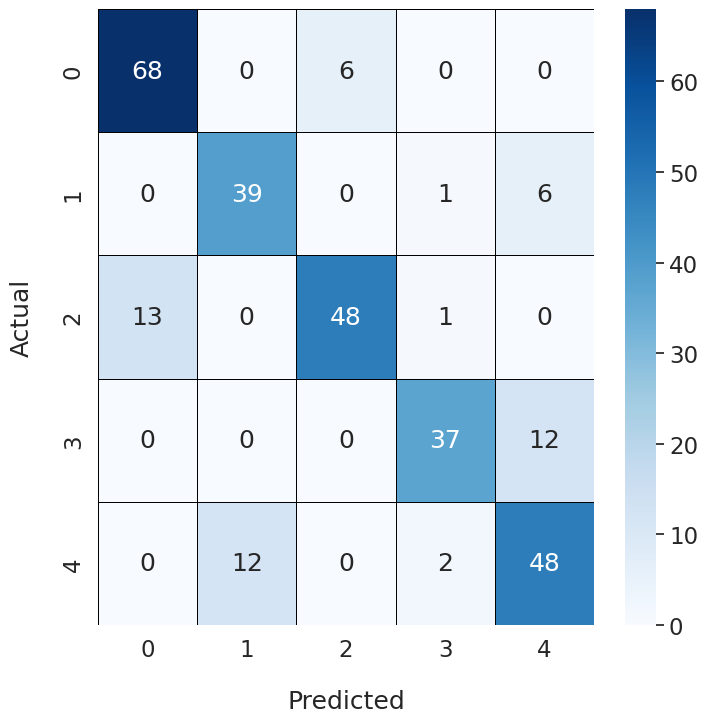

Epoch Training Time: 1496.85 seconds
Test set: Average loss: 0.4162, Accuracy: 274/323 (84.83%), F1 Score: 0.8479

Fold 2
-------
Early stopping at epoch 151 due to no improvement in validation loss.


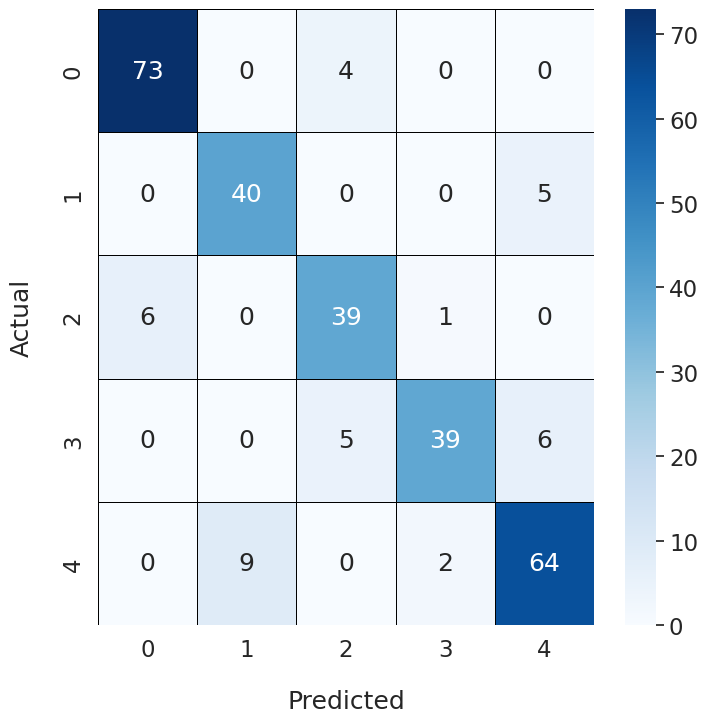

Epoch Training Time: 1589.53 seconds
Test set: Average loss: 0.4551, Accuracy: 275/323 (85.14%), F1 Score: 0.8484

Fold 3
-------
Early stopping at epoch 133 due to no improvement in validation loss.


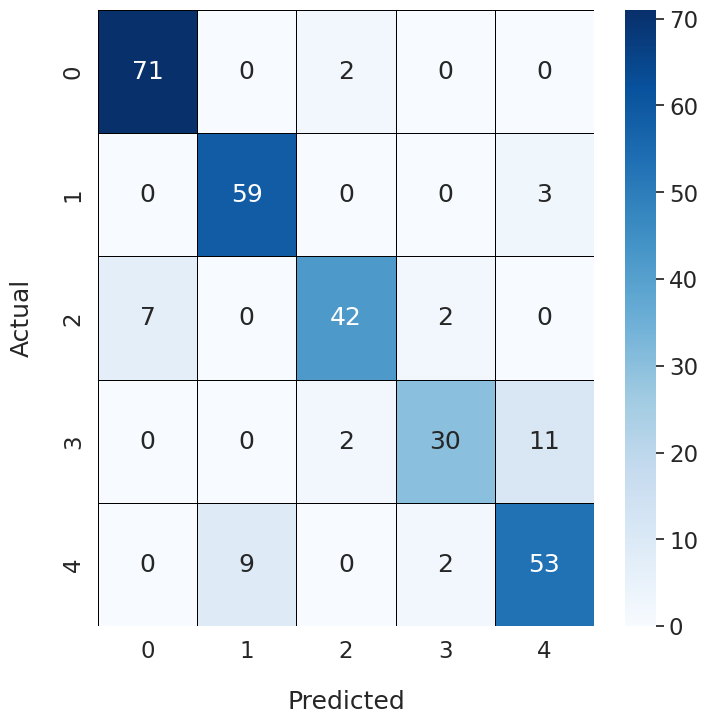

Epoch Training Time: 1400.25 seconds
Test set: Average loss: 0.4494, Accuracy: 273/323 (84.52%), F1 Score: 0.8424

Fold 4
-------
Early stopping at epoch 150 due to no improvement in validation loss.


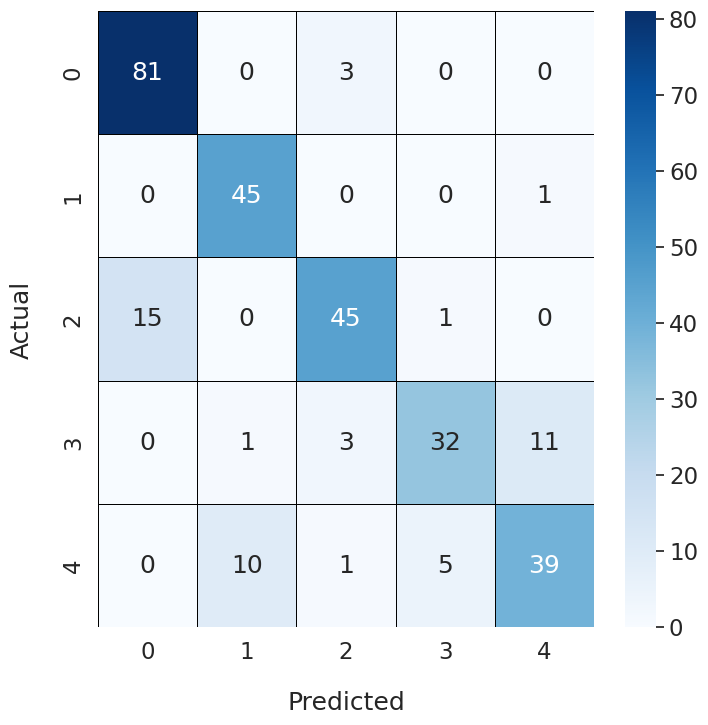

Epoch Training Time: 1579.28 seconds
Test set: Average loss: 0.4796, Accuracy: 270/323 (83.59%), F1 Score: 0.8334

Fold 5
-------
Early stopping at epoch 141 due to no improvement in validation loss.


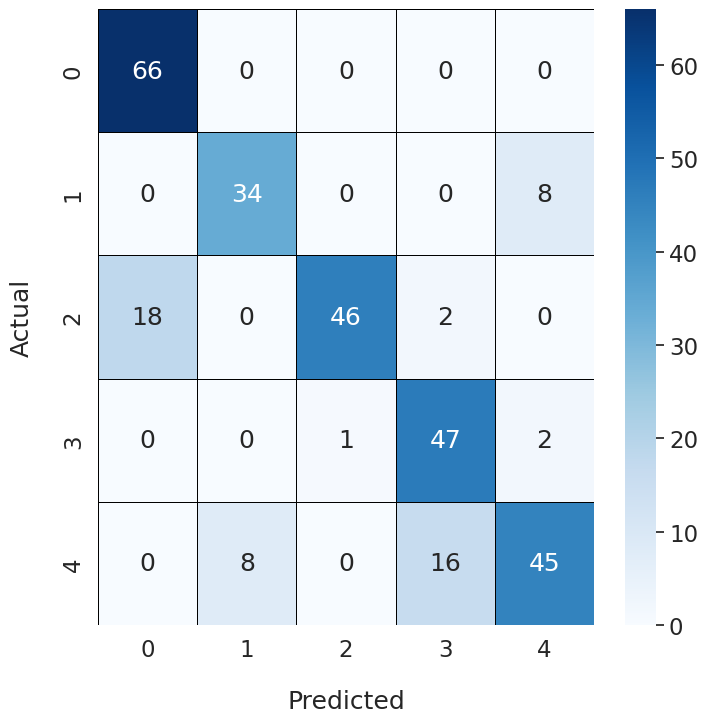

Epoch Training Time: 1484.64 seconds
Test set: Average loss: 0.4289, Accuracy: 268/323 (82.97%), F1 Score: 0.8289

Fold 6
-------
Early stopping at epoch 155 due to no improvement in validation loss.


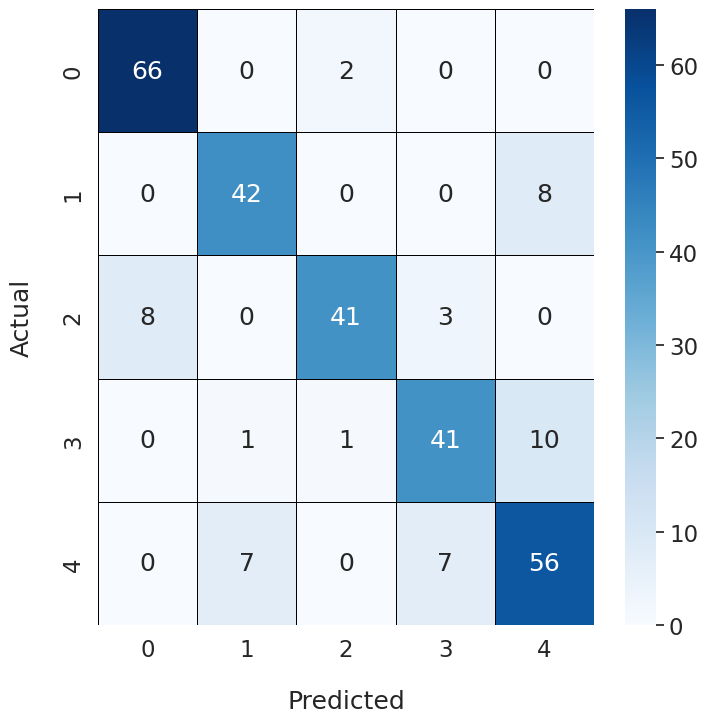

Epoch Training Time: 1631.46 seconds
Test set: Average loss: 0.4689, Accuracy: 270/323 (83.59%), F1 Score: 0.8350

Fold 7
-------
Early stopping at epoch 152 due to no improvement in validation loss.


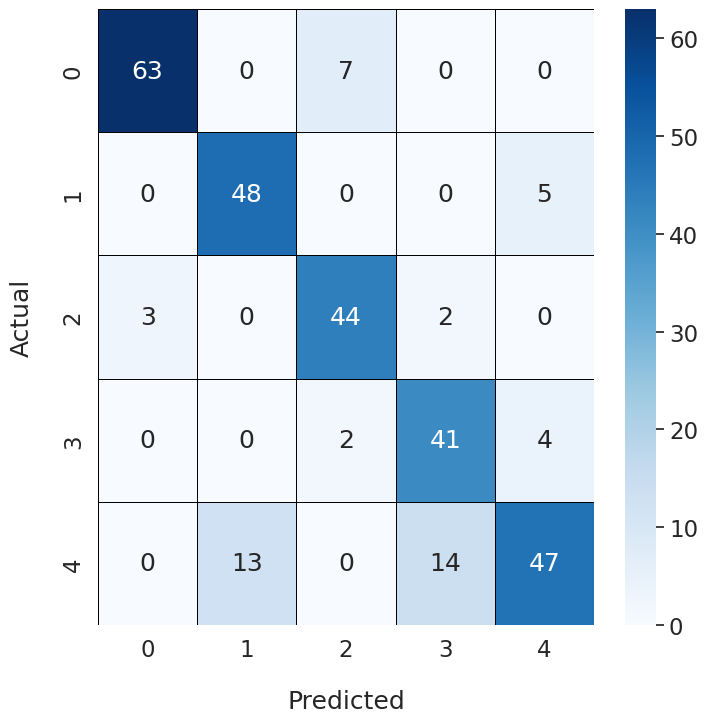

Epoch Training Time: 1600.87 seconds
Test set: Average loss: 0.4518, Accuracy: 269/323 (83.28%), F1 Score: 0.8312

Fold 8
-------
Early stopping at epoch 142 due to no improvement in validation loss.


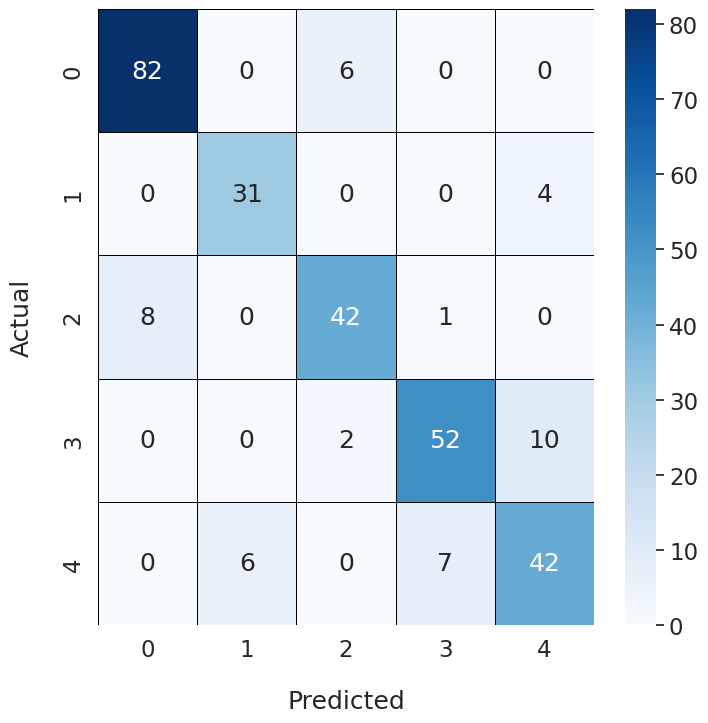

Epoch Training Time: 1494.92 seconds
Test set: Average loss: 0.4231, Accuracy: 270/323 (83.59%), F1 Score: 0.8343

Fold 9
-------
Early stopping at epoch 143 due to no improvement in validation loss.


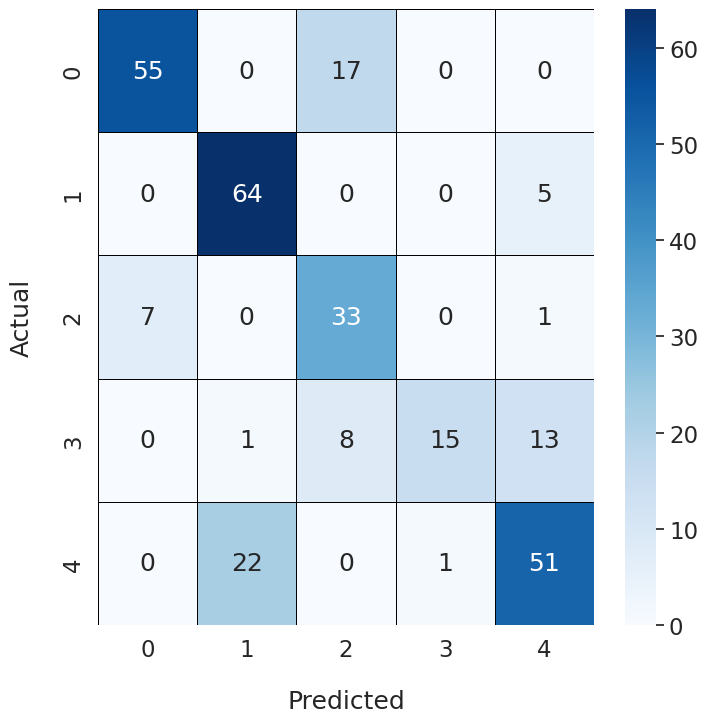

Epoch Training Time: 1504.28 seconds
Test set: Average loss: 0.4112, Accuracy: 269/323 (83.28%), F1 Score: 0.8298

Fold 10
-------
Early stopping at epoch 138 due to no improvement in validation loss.


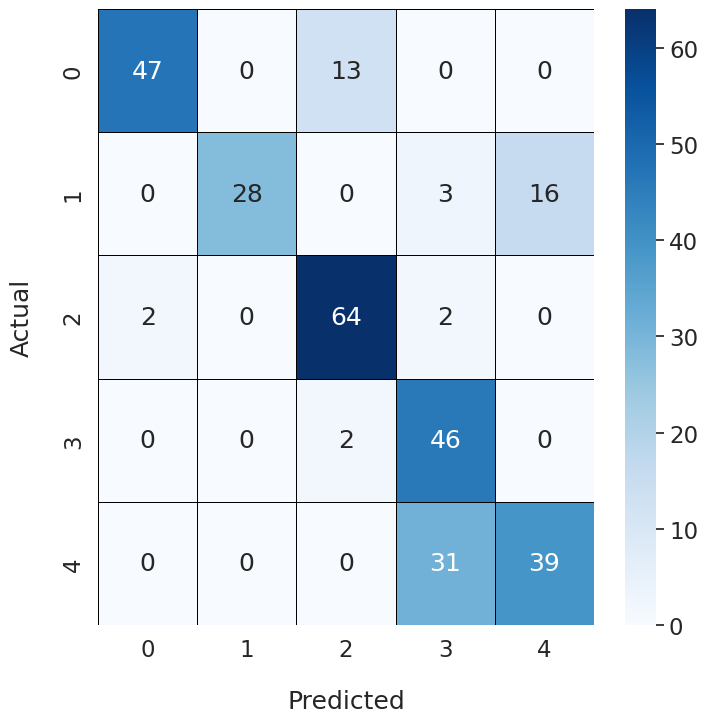

Epoch Training Time: 1453.26 seconds
Test set: Average loss: 0.4091, Accuracy: 275/323 (85.14%), F1 Score: 0.8497


Total training time for 10 folds: 15235.32 seconds


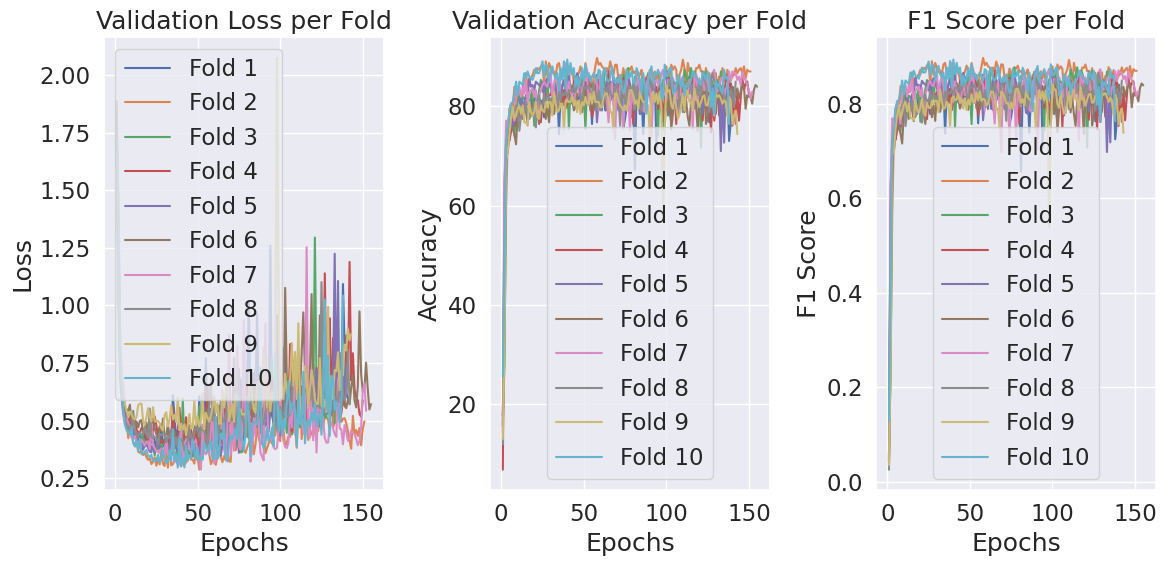

Maximum Fold Accuracy = 85.13931888544892
Maximum Fold F1 Score = 0.8497263929911044
Average Fold Accuracy = 83.99380804953562
Average Fold F1 Score = 0.838108543429515


In [4]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Darknet/noSE"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Darknet/noSE/best_noSE.pth"
os.makedirs("./model_Darknet/noSE", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_noSE.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []

   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )
    # Initialize the model and optimizer
    model = darknet53(5).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1

    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves, epochs_f1_score=epochs_f1_score
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop
                
    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")
    
    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"noSE_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])

    all_folds_val_loss.append(epoch_val_loss.copy())
    all_folds_val_acc.append(epoch_val_acc.copy())
    all_folds_f1.append(epochs_f1_score.copy())

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = darknet53(5).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [5]:
import gc
import torch
import numpy as np
import os
import sys

def clear_all_memory():
    # Clear CUDA memory (VRAM)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    
    # Collect garbage (clean up unused memory from the Python heap)
    gc.collect()

    # Delete variables to free RAM
    for name in dir():
        if not name.startswith('_'):
            del globals()[name]

    # Reset random seeds if necessary
    np.random.seed(42)
    torch.manual_seed(42)
    torch.cuda.manual_seed(42)
    torch.backends.cudnn.deterministic = True

    # Optional: Reset environment variables or modules if needed (e.g., clearing caches)
    os.environ["CUDA_VISIBLE_DEVICES"] = ""

    print("Memory cleared and environment reset!")

# Call this function when you want to clear everything out
clear_all_memory()

Memory cleared and environment reset!


SE(avg original) + Darknet53-------------------------------------------------------------------------------------------

In [6]:
import import_ipynb
from starter_Darknet53 import *

In [7]:
class SE_Block(nn.Module):
    "credits: https://github.com/moskomule/senet.pytorch/blob/master/senet/se_module.py#L4"
    def __init__(self, c, r=16):
        super().__init__()
        self.squeeze = nn.AdaptiveAvgPool2d(1)
        self.excitation = nn.Sequential(
            nn.Linear(c, c // r, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(c // r, c, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        bs, c, _, _ = x.shape
        y = self.squeeze(x).view(bs, c)
        y = self.excitation(y).view(bs, c, 1, 1)
        return x * y.expand_as(x)

In [8]:
def conv_batch(in_num, out_num, kernel_size=3, padding=1, stride=1):
    return nn.Sequential(
        nn.Conv2d(in_num, out_num, kernel_size=kernel_size, stride=stride, padding=padding, bias=False),
        nn.BatchNorm2d(out_num),
        nn.LeakyReLU())


# Residual block
class DarkResidualBlock(nn.Module):
    def __init__(self, in_channels, r=16):
        super(DarkResidualBlock, self).__init__()

        reduced_channels = int(in_channels/2)

        self.layer1 = conv_batch(in_channels, reduced_channels, kernel_size=1, padding=0)
        self.layer2 = conv_batch(reduced_channels, in_channels)
        self.se = SE_Block(in_channels, r)

    def forward(self, x):
        residual = x

        out = self.layer1(x)
        out = self.layer2(out)

        out = self.se(out)
        
        out += residual
        return out


class Darknet53(nn.Module):
    def __init__(self, block, num_classes):
        super(Darknet53, self).__init__()

        self.num_classes = num_classes

        self.conv1 = conv_batch(3, 32)
        self.conv2 = conv_batch(32, 64, stride=2)
        self.residual_block1 = self.make_layer(block, in_channels=64, num_blocks=1)
        self.conv3 = conv_batch(64, 128, stride=2)
        self.residual_block2 = self.make_layer(block, in_channels=128, num_blocks=2)
        self.conv4 = conv_batch(128, 256, stride=2)
        self.residual_block3 = self.make_layer(block, in_channels=256, num_blocks=8)
        self.conv5 = conv_batch(256, 512, stride=2)
        self.residual_block4 = self.make_layer(block, in_channels=512, num_blocks=8)
        self.conv6 = conv_batch(512, 1024, stride=2)
        self.residual_block5 = self.make_layer(block, in_channels=1024, num_blocks=4)
        self.global_avg_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(1024, self.num_classes)

    def forward(self, x):
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.residual_block1(out)
        out = self.conv3(out)
        out = self.residual_block2(out)
        out = self.conv4(out)
        out = self.residual_block3(out)
        out = self.conv5(out)
        out = self.residual_block4(out)
        out = self.conv6(out)
        out = self.residual_block5(out)
        out = self.global_avg_pool(out)
        out = out.view(-1, 1024)
        out = self.fc(out)

        return out

    def make_layer(self, block, in_channels, num_blocks):
        layers = []
        for i in range(0, num_blocks):
            layers.append(block(in_channels))
        return nn.Sequential(*layers)


def darknet53(num_classes):
    return Darknet53(DarkResidualBlock, num_classes)

In [9]:
all_folds_val_loss = []
all_folds_val_acc = []
all_folds_f1 = []
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 9.33 GMac
Model Params: 41.45 M
Early stopping at epoch 163 due to no improvement in validation loss.


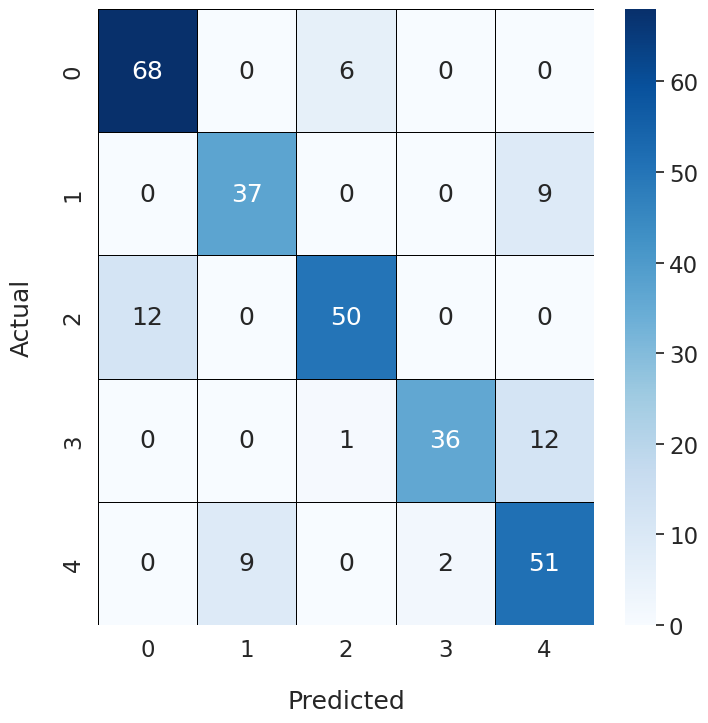

Epoch Training Time: 1871.42 seconds
Test set: Average loss: 0.4224, Accuracy: 265/323 (82.04%), F1 Score: 0.8204

Fold 2
-------
Early stopping at epoch 197 due to no improvement in validation loss.


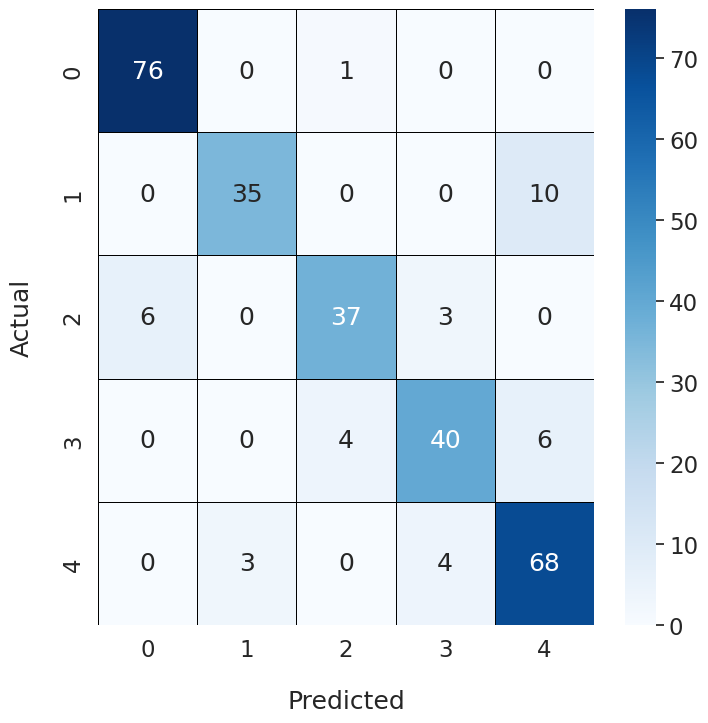

Epoch Training Time: 2264.42 seconds
Test set: Average loss: 0.4210, Accuracy: 270/323 (83.59%), F1 Score: 0.8342

Fold 3
-------
Early stopping at epoch 192 due to no improvement in validation loss.


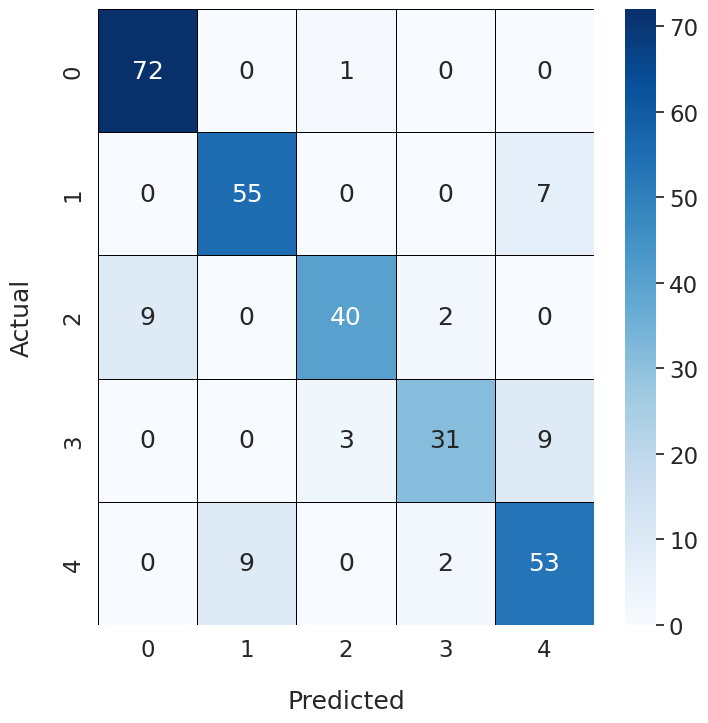

Epoch Training Time: 2207.62 seconds
Test set: Average loss: 0.4229, Accuracy: 272/323 (84.21%), F1 Score: 0.8407

Fold 4
-------
Early stopping at epoch 234 due to no improvement in validation loss.


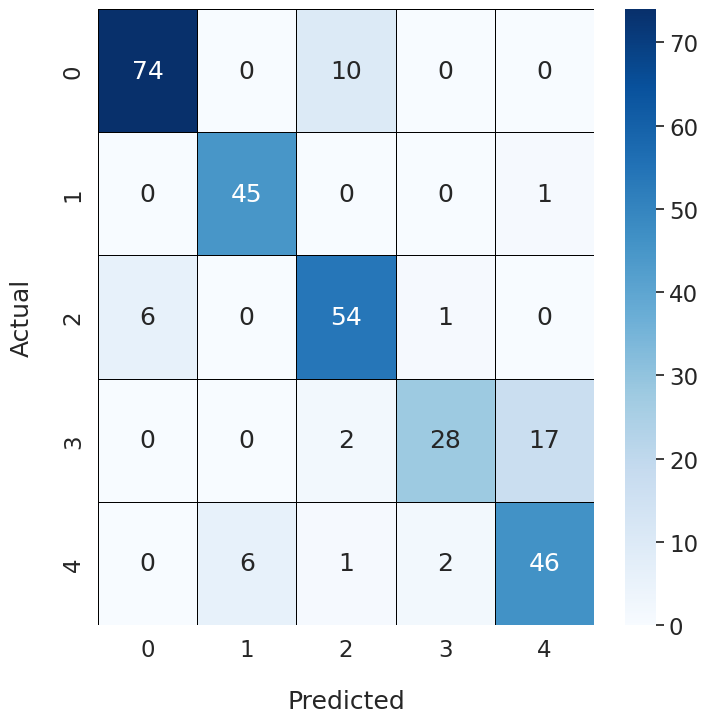

Epoch Training Time: 2689.65 seconds
Test set: Average loss: 0.4405, Accuracy: 276/323 (85.45%), F1 Score: 0.8530

Fold 5
-------
Early stopping at epoch 191 due to no improvement in validation loss.


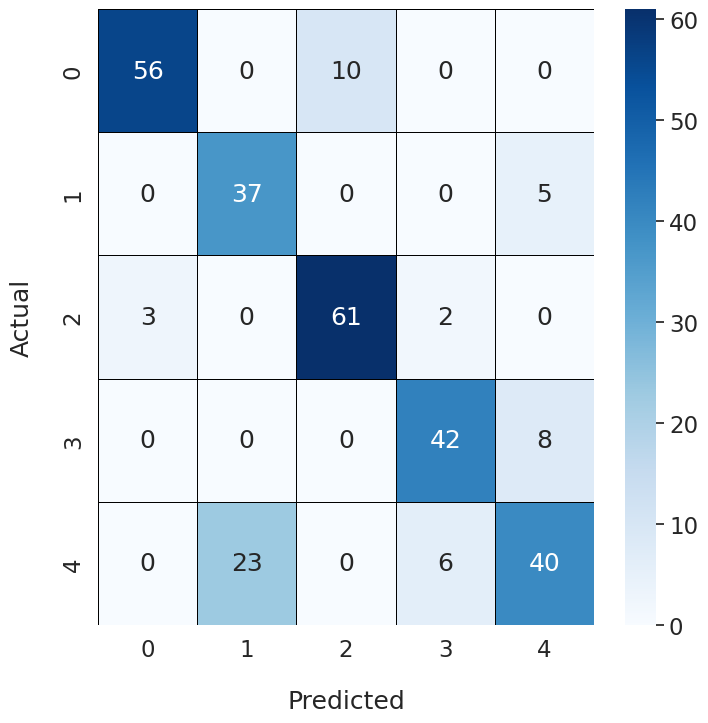

Epoch Training Time: 2194.22 seconds
Test set: Average loss: 0.4082, Accuracy: 272/323 (84.21%), F1 Score: 0.8417

Fold 6
-------
Early stopping at epoch 204 due to no improvement in validation loss.


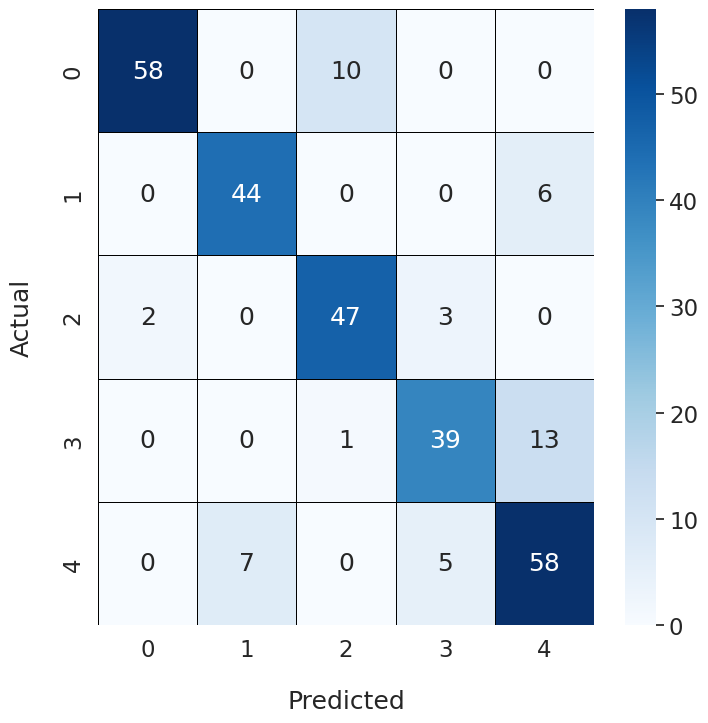

Epoch Training Time: 2344.24 seconds
Test set: Average loss: 0.4365, Accuracy: 270/323 (83.59%), F1 Score: 0.8348

Fold 7
-------
Early stopping at epoch 206 due to no improvement in validation loss.


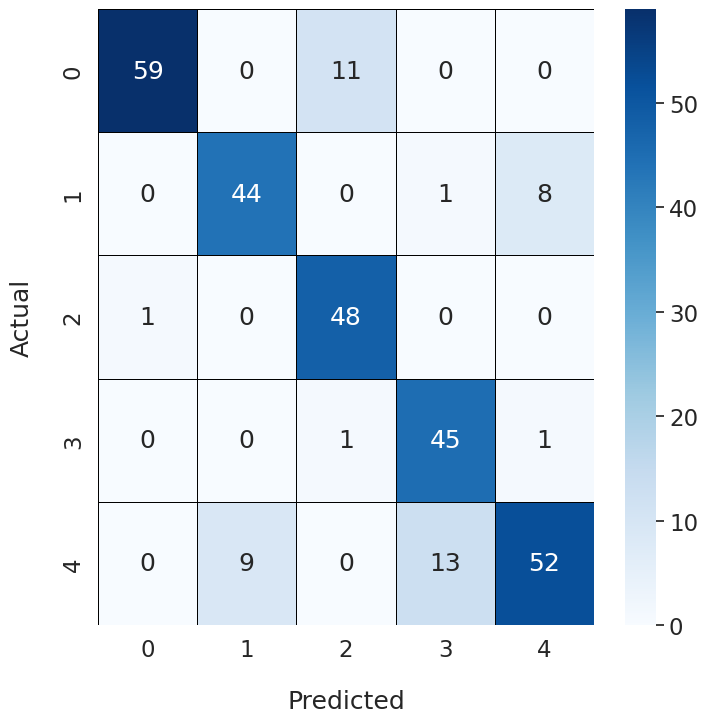

Epoch Training Time: 2372.12 seconds
Test set: Average loss: 0.4596, Accuracy: 271/323 (83.90%), F1 Score: 0.8363

Fold 8
-------
Early stopping at epoch 157 due to no improvement in validation loss.


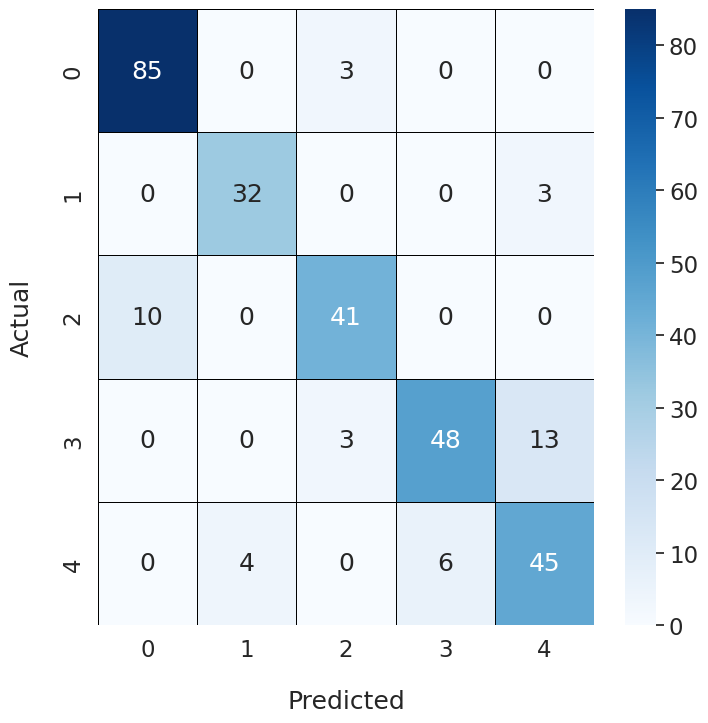

Epoch Training Time: 1809.24 seconds
Test set: Average loss: 0.4238, Accuracy: 268/323 (82.97%), F1 Score: 0.8275

Fold 9
-------
Early stopping at epoch 152 due to no improvement in validation loss.


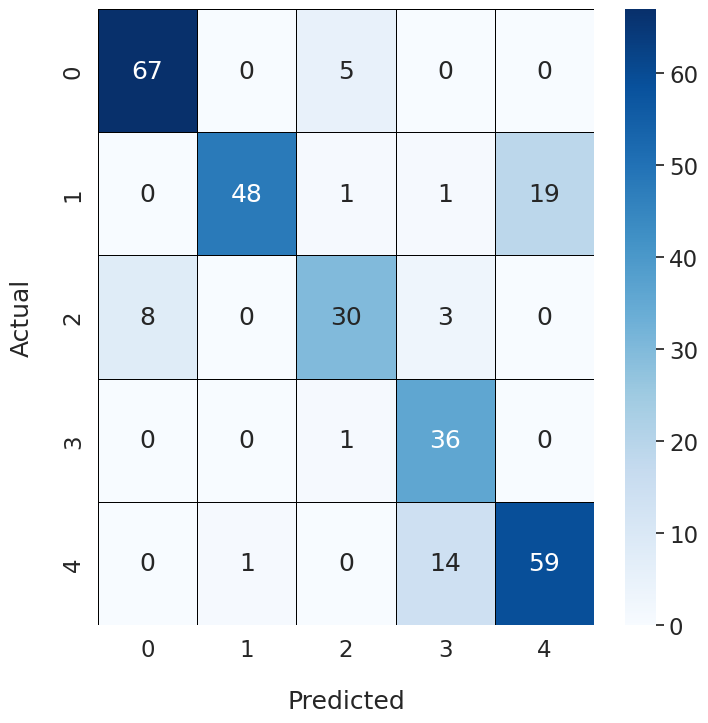

Epoch Training Time: 1750.28 seconds
Test set: Average loss: 0.4318, Accuracy: 264/323 (81.73%), F1 Score: 0.8147

Fold 10
-------
Early stopping at epoch 184 due to no improvement in validation loss.


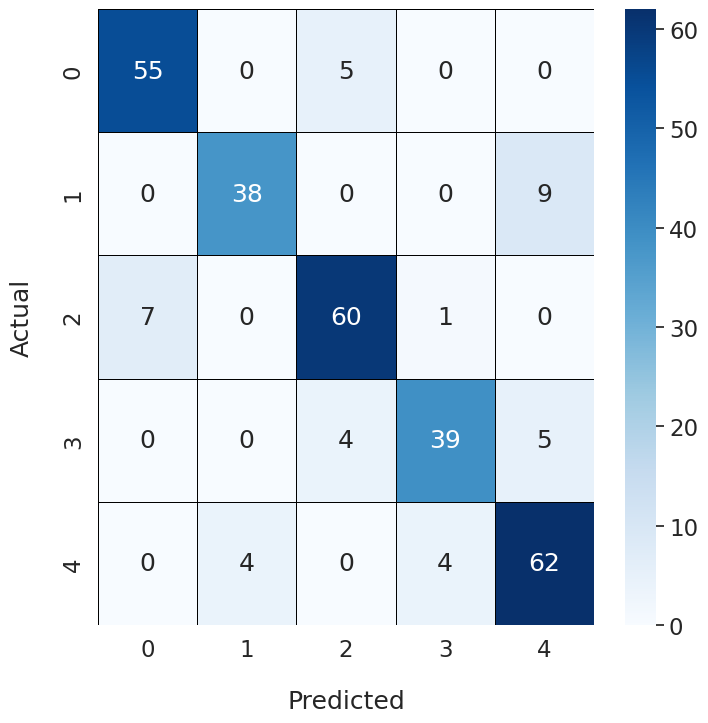

Epoch Training Time: 2120.00 seconds
Test set: Average loss: 0.4331, Accuracy: 274/323 (84.83%), F1 Score: 0.8470


Total training time for 10 folds: 21623.21 seconds


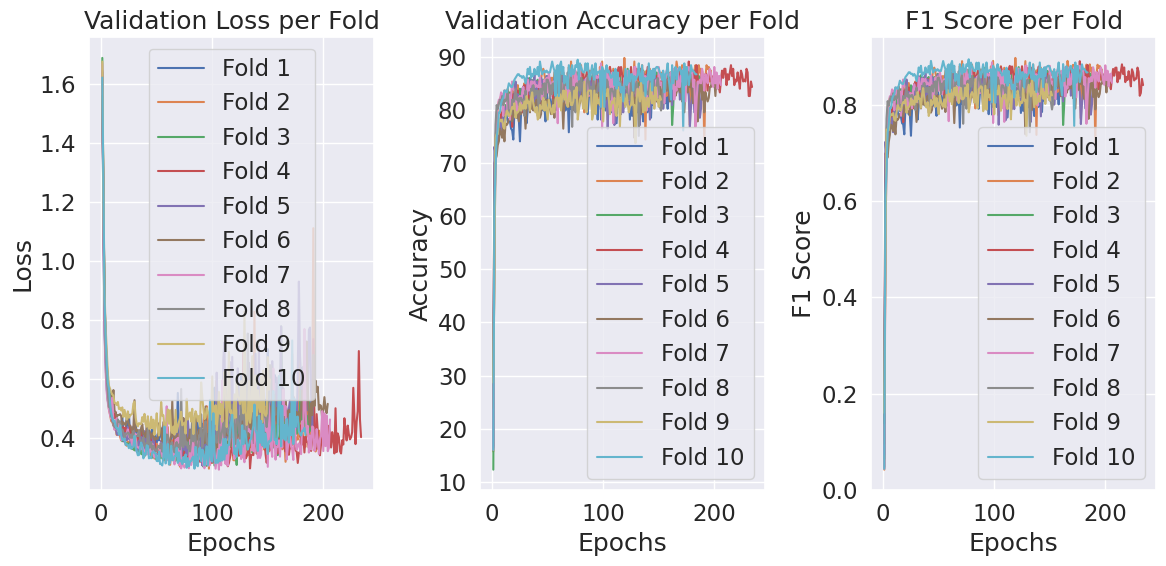

Maximum Fold Accuracy = 85.44891640866874
Maximum Fold F1 Score = 0.8530432875763952
Average Fold Accuracy = 83.65325077399382
Average Fold F1 Score = 0.8350459804315845


In [10]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Darknet/SE_avg"
os.makedirs(save_dir, exist_ok=True)

model_save_path = "./model_Darknet/SE_avg/best_SE_avg.pth"
os.makedirs("./model_Darknet/SE_avg", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_SEavg.txt")
#sys.stdout = open(log_file_path, 'w')

print_count = 0

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )

    # Initialize the model and optimizer
    model = darknet53(5).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
          
    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop
                
    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEavg_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])

    all_folds_val_loss.append(epoch_val_loss.copy())
    all_folds_val_acc.append(epoch_val_acc.copy())
    all_folds_f1.append(epochs_f1_score.copy())
            
    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = darknet53(5).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [11]:
clear_all_memory()

Memory cleared and environment reset!


SE(max)+Darknet----------------------------------------------------------------------------------------------------------

In [12]:
import import_ipynb
from starter_Darknet53 import *

In [13]:
class SE_Block_max(nn.Module):
    "credits: https://github.com/moskomule/senet.pytorch/blob/master/senet/se_module.py#L4"
    def __init__(self, c, r=16):
        super().__init__()
        self.squeeze = nn.AdaptiveMaxPool2d(1)
        self.excitation = nn.Sequential(
            nn.Linear(c, c // r, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(c // r, c, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        bs, c, _, _ = x.shape
        y = self.squeeze(x).view(bs, c)
        y = self.excitation(y).view(bs, c, 1, 1)
        return x * y.expand_as(x)

In [14]:
def conv_batch(in_num, out_num, kernel_size=3, padding=1, stride=1):
    return nn.Sequential(
        nn.Conv2d(in_num, out_num, kernel_size=kernel_size, stride=stride, padding=padding, bias=False),
        nn.BatchNorm2d(out_num),
        nn.LeakyReLU())


# Residual block
class DarkResidualBlock(nn.Module):
    def __init__(self, in_channels, r=16):
        super(DarkResidualBlock, self).__init__()

        reduced_channels = int(in_channels/2)

        self.layer1 = conv_batch(in_channels, reduced_channels, kernel_size=1, padding=0)
        self.layer2 = conv_batch(reduced_channels, in_channels)
        self.se = SE_Block_max(in_channels, r)

    def forward(self, x):
        residual = x

        out = self.layer1(x)
        out = self.layer2(out)

        out = self.se(out)
        
        out += residual
        return out


class Darknet53(nn.Module):
    def __init__(self, block, num_classes):
        super(Darknet53, self).__init__()

        self.num_classes = num_classes

        self.conv1 = conv_batch(3, 32)
        self.conv2 = conv_batch(32, 64, stride=2)
        self.residual_block1 = self.make_layer(block, in_channels=64, num_blocks=1)
        self.conv3 = conv_batch(64, 128, stride=2)
        self.residual_block2 = self.make_layer(block, in_channels=128, num_blocks=2)
        self.conv4 = conv_batch(128, 256, stride=2)
        self.residual_block3 = self.make_layer(block, in_channels=256, num_blocks=8)
        self.conv5 = conv_batch(256, 512, stride=2)
        self.residual_block4 = self.make_layer(block, in_channels=512, num_blocks=8)
        self.conv6 = conv_batch(512, 1024, stride=2)
        self.residual_block5 = self.make_layer(block, in_channels=1024, num_blocks=4)
        self.global_avg_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(1024, self.num_classes)

    def forward(self, x):
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.residual_block1(out)
        out = self.conv3(out)
        out = self.residual_block2(out)
        out = self.conv4(out)
        out = self.residual_block3(out)
        out = self.conv5(out)
        out = self.residual_block4(out)
        out = self.conv6(out)
        out = self.residual_block5(out)
        out = self.global_avg_pool(out)
        out = out.view(-1, 1024)
        out = self.fc(out)

        return out

    def make_layer(self, block, in_channels, num_blocks):
        layers = []
        for i in range(0, num_blocks):
            layers.append(block(in_channels))
        return nn.Sequential(*layers)


def darknet53(num_classes):
    return Darknet53(DarkResidualBlock, num_classes)

In [15]:
all_folds_val_loss = [] 
all_folds_val_acc = [] 
all_folds_f1 = []
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 9.33 GMac
Model Params: 41.45 M
Early stopping at epoch 140 due to no improvement in validation loss.


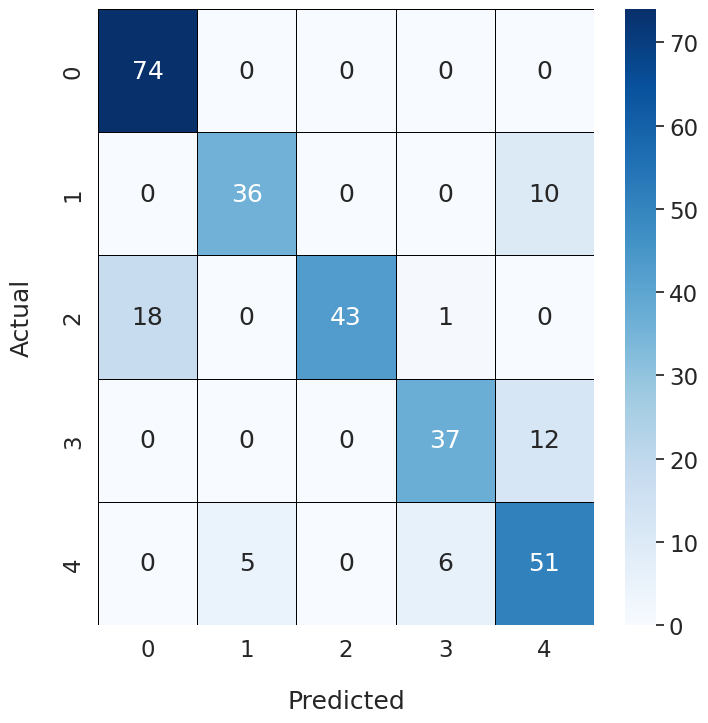

Epoch Training Time: 1779.90 seconds
Test set: Average loss: 0.4028, Accuracy: 273/323 (84.52%), F1 Score: 0.8447

Fold 2
-------
Early stopping at epoch 142 due to no improvement in validation loss.


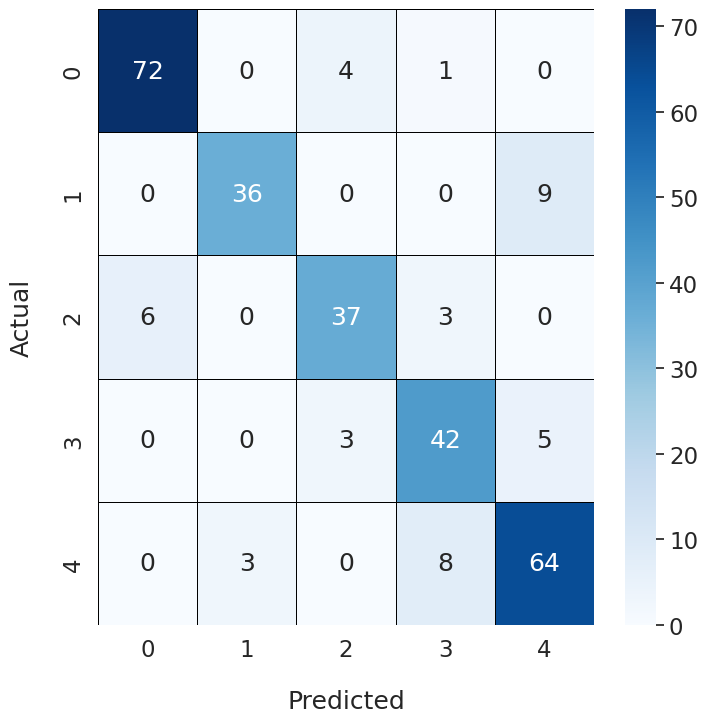

Epoch Training Time: 1804.39 seconds
Test set: Average loss: 0.3959, Accuracy: 275/323 (85.14%), F1 Score: 0.8504

Fold 3
-------
Early stopping at epoch 149 due to no improvement in validation loss.


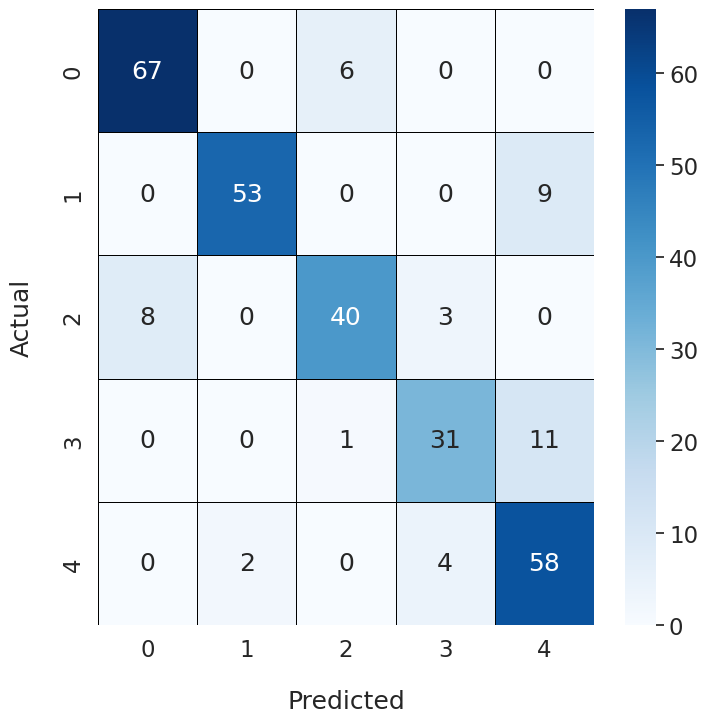

Epoch Training Time: 1892.47 seconds
Test set: Average loss: 0.4455, Accuracy: 265/323 (82.04%), F1 Score: 0.8182

Fold 4
-------
Early stopping at epoch 177 due to no improvement in validation loss.


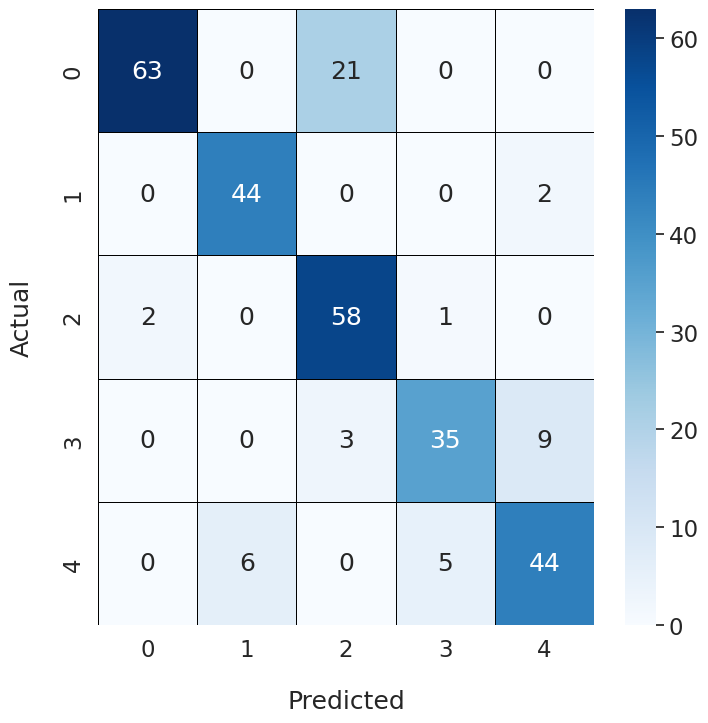

Epoch Training Time: 2249.38 seconds
Test set: Average loss: 0.5425, Accuracy: 271/323 (83.90%), F1 Score: 0.8384

Fold 5
-------
Early stopping at epoch 136 due to no improvement in validation loss.


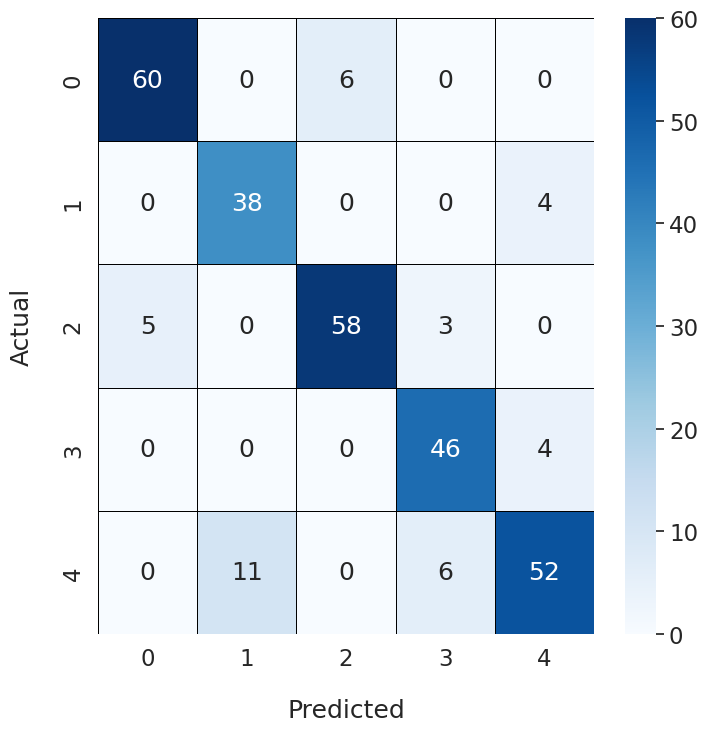

Epoch Training Time: 1728.69 seconds
Test set: Average loss: 0.4154, Accuracy: 266/323 (82.35%), F1 Score: 0.8214

Fold 6
-------
Early stopping at epoch 158 due to no improvement in validation loss.


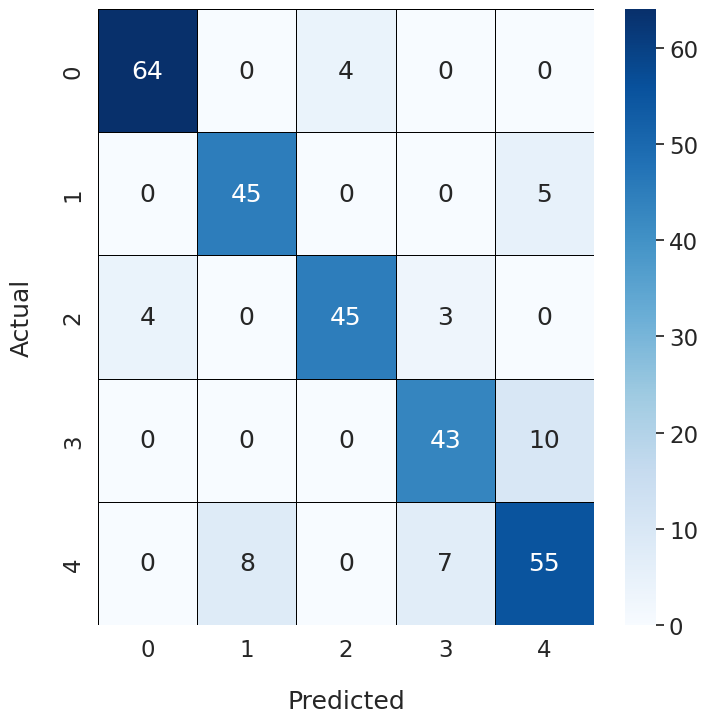

Epoch Training Time: 2006.93 seconds
Test set: Average loss: 0.4386, Accuracy: 270/323 (83.59%), F1 Score: 0.8354

Fold 7
-------
Early stopping at epoch 144 due to no improvement in validation loss.


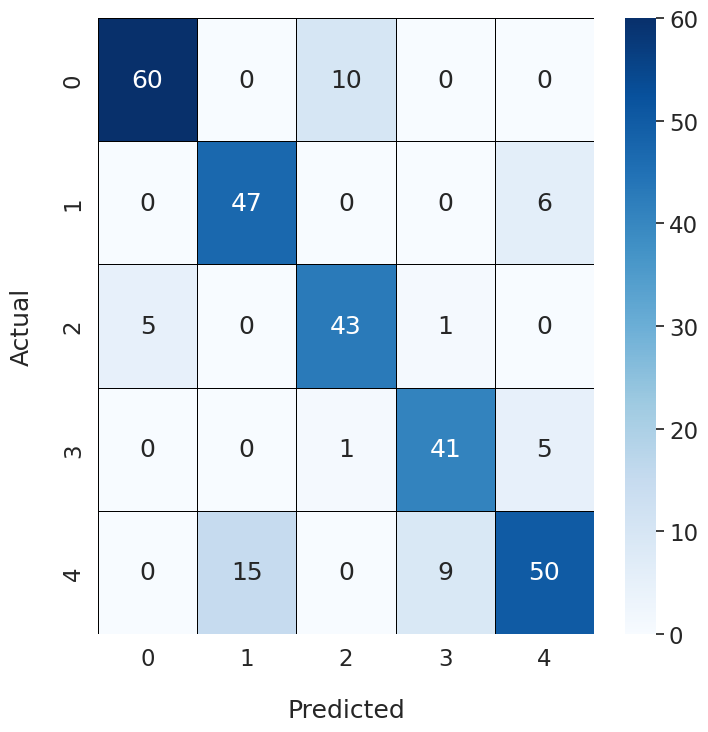

Epoch Training Time: 1830.42 seconds
Test set: Average loss: 0.4420, Accuracy: 265/323 (82.04%), F1 Score: 0.8166

Fold 8
-------
Early stopping at epoch 133 due to no improvement in validation loss.


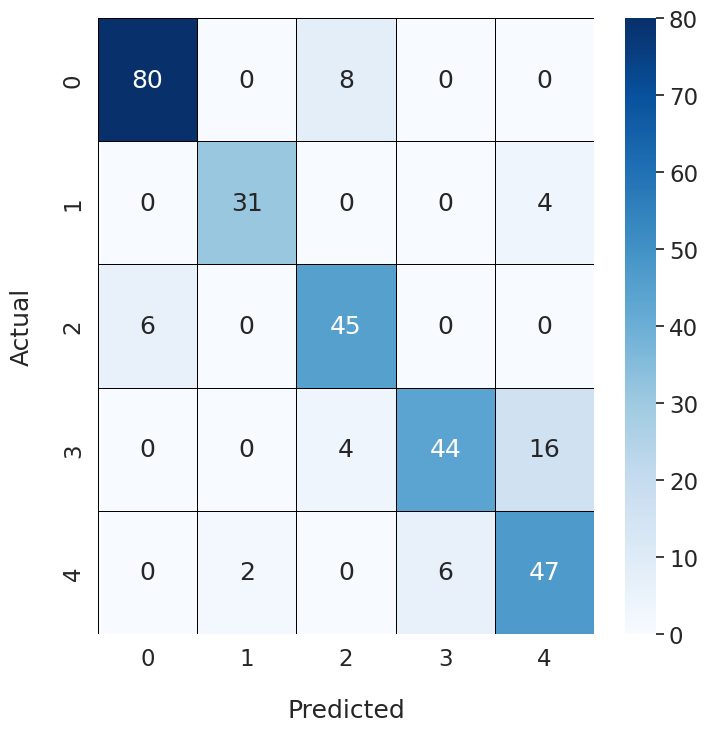

Epoch Training Time: 1689.02 seconds
Test set: Average loss: 0.4042, Accuracy: 272/323 (84.21%), F1 Score: 0.8416

Fold 9
-------
Early stopping at epoch 134 due to no improvement in validation loss.


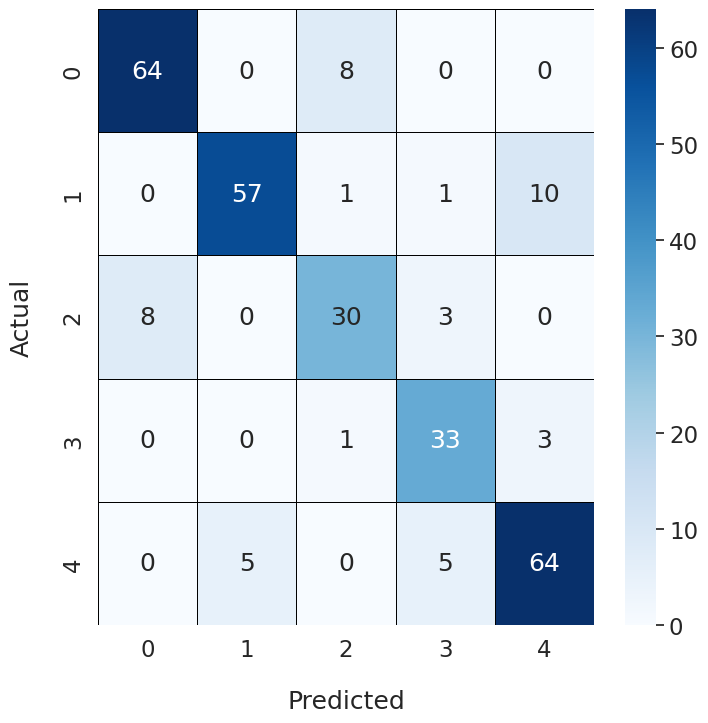

Epoch Training Time: 1702.76 seconds
Test set: Average loss: 0.4354, Accuracy: 266/323 (82.35%), F1 Score: 0.8201

Fold 10
-------
Early stopping at epoch 146 due to no improvement in validation loss.


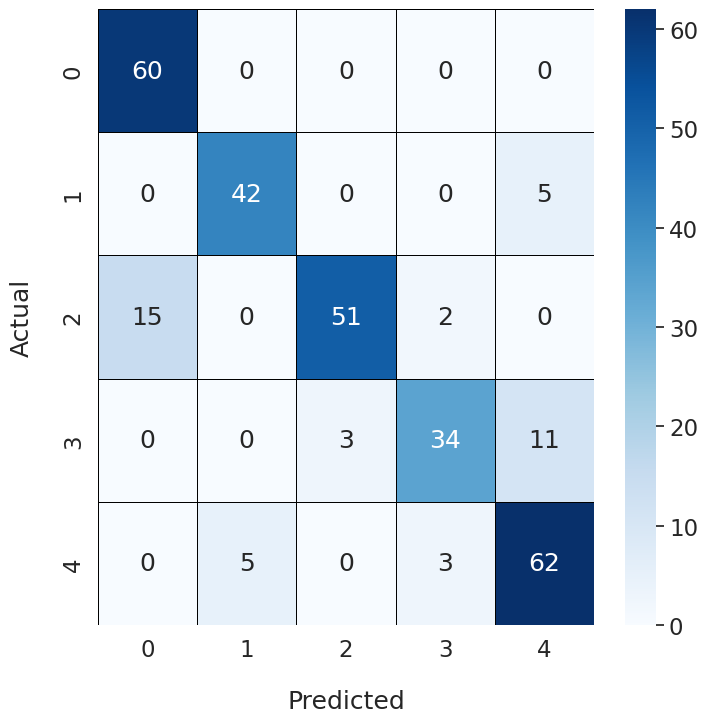

Epoch Training Time: 1856.47 seconds
Test set: Average loss: 0.3755, Accuracy: 277/323 (85.76%), F1 Score: 0.8559


Total training time for 10 folds: 18540.44 seconds


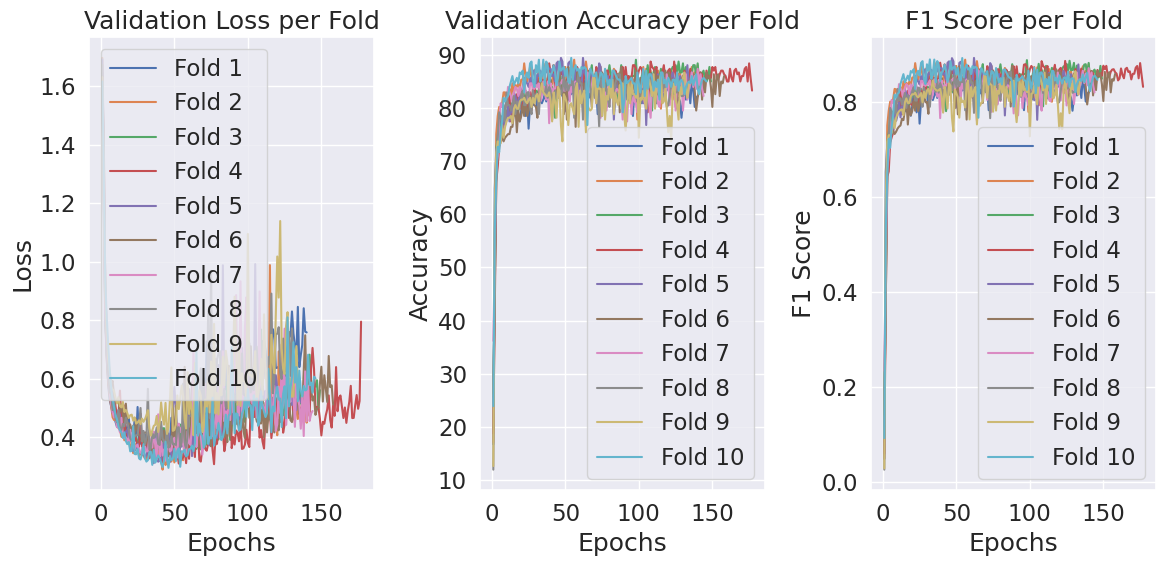

Maximum Fold Accuracy = 85.75851393188854
Maximum Fold F1 Score = 0.8558712983928621
Average Fold Accuracy = 83.59133126934984
Average Fold F1 Score = 0.8342918764172499


In [16]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Darknet/SE_max"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Darknet/SE_max/best_SE_max.pth"
os.makedirs("./model_Darknet/SE_max", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_SEmax.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []

   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )

    # Initialize the model and optimizer
    model = darknet53(5).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEmax_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------
    

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    best_model = darknet53(5).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    

max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [17]:
clear_all_memory()

Memory cleared and environment reset!


SE mixed pool + Darknet53---------------------------------------------------------------------------------------

In [18]:
from Mixedpool05 import mixedPool

alpha = 0.5


In [19]:
import import_ipynb
from starter_Darknet53 import *

In [20]:
class SE_Block_mix(nn.Module):
    "credits: https://github.com/moskomule/senet.pytorch/blob/master/senet/se_module.py#L4"
    def __init__(self, c, r=16):
        super().__init__()
        self.squeeze = mixedPool()
        self.excitation = nn.Sequential(
            nn.Linear(c, c // r, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(c // r, c, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        bs, c, _, _ = x.shape
        y = self.squeeze(x).view(bs, c)
        y = self.excitation(y).view(bs, c, 1, 1)
        return x * y.expand_as(x)

In [21]:
def conv_batch(in_num, out_num, kernel_size=3, padding=1, stride=1):
    return nn.Sequential(
        nn.Conv2d(in_num, out_num, kernel_size=kernel_size, stride=stride, padding=padding, bias=False),
        nn.BatchNorm2d(out_num),
        nn.LeakyReLU())


# Residual block
class DarkResidualBlock(nn.Module):
    def __init__(self, in_channels, r=16):
        super(DarkResidualBlock, self).__init__()

        reduced_channels = int(in_channels/2)

        self.layer1 = conv_batch(in_channels, reduced_channels, kernel_size=1, padding=0)
        self.layer2 = conv_batch(reduced_channels, in_channels)
        self.se = SE_Block_mix(in_channels, r)

    def forward(self, x):
        residual = x

        out = self.layer1(x)
        out = self.layer2(out)

        out = self.se(out)
        
        out += residual
        return out


class Darknet53(nn.Module):
    def __init__(self, block, num_classes):
        super(Darknet53, self).__init__()

        self.num_classes = num_classes

        self.conv1 = conv_batch(3, 32)
        self.conv2 = conv_batch(32, 64, stride=2)
        self.residual_block1 = self.make_layer(block, in_channels=64, num_blocks=1)
        self.conv3 = conv_batch(64, 128, stride=2)
        self.residual_block2 = self.make_layer(block, in_channels=128, num_blocks=2)
        self.conv4 = conv_batch(128, 256, stride=2)
        self.residual_block3 = self.make_layer(block, in_channels=256, num_blocks=8)
        self.conv5 = conv_batch(256, 512, stride=2)
        self.residual_block4 = self.make_layer(block, in_channels=512, num_blocks=8)
        self.conv6 = conv_batch(512, 1024, stride=2)
        self.residual_block5 = self.make_layer(block, in_channels=1024, num_blocks=4)
        self.global_avg_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(1024, self.num_classes)

    def forward(self, x):
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.residual_block1(out)
        out = self.conv3(out)
        out = self.residual_block2(out)
        out = self.conv4(out)
        out = self.residual_block3(out)
        out = self.conv5(out)
        out = self.residual_block4(out)
        out = self.conv6(out)
        out = self.residual_block5(out)
        out = self.global_avg_pool(out)
        out = out.view(-1, 1024)
        out = self.fc(out)

        return out

    def make_layer(self, block, in_channels, num_blocks):
        layers = []
        for i in range(0, num_blocks):
            layers.append(block(in_channels))
        return nn.Sequential(*layers)


def darknet53(num_classes):
    return Darknet53(DarkResidualBlock, num_classes)

In [22]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 9.33 GMac
Model Params: 41.45 M
Early stopping at epoch 153 due to no improvement in validation loss.


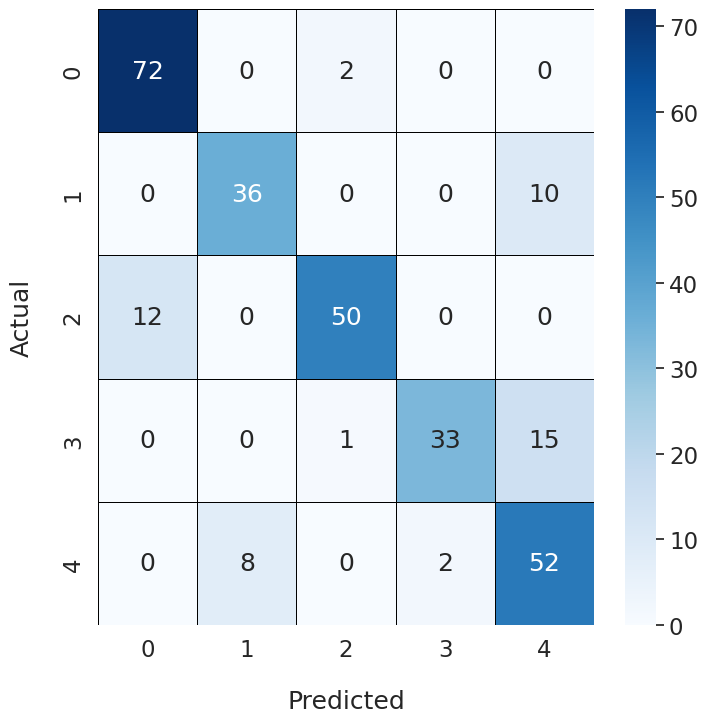

Epoch Training Time: 2001.75 seconds
Test set: Average loss: 0.3759, Accuracy: 277/323 (85.76%), F1 Score: 0.8566

Fold 2
-------
Early stopping at epoch 155 due to no improvement in validation loss.


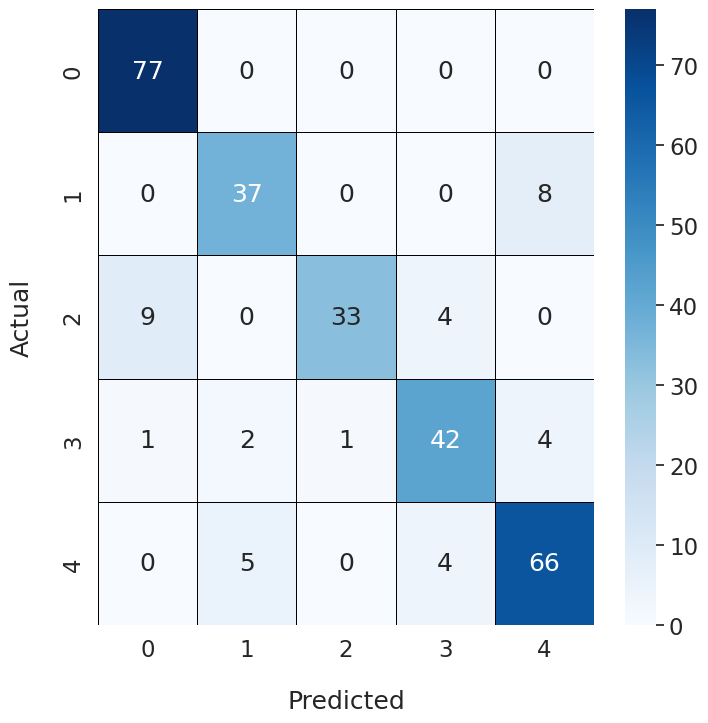

Epoch Training Time: 2029.36 seconds
Test set: Average loss: 0.4047, Accuracy: 273/323 (84.52%), F1 Score: 0.8426

Fold 3
-------
Early stopping at epoch 173 due to no improvement in validation loss.


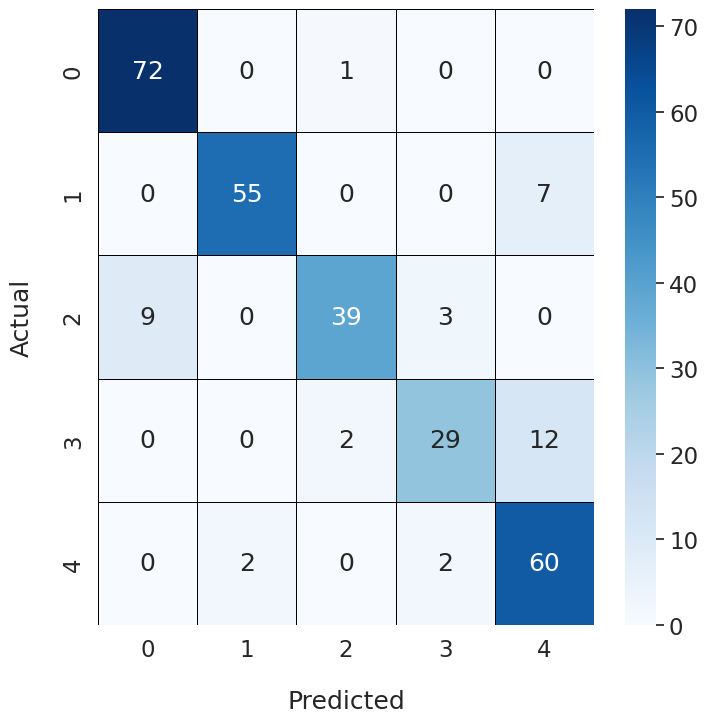

Epoch Training Time: 2264.89 seconds
Test set: Average loss: 0.4476, Accuracy: 267/323 (82.66%), F1 Score: 0.8246

Fold 4
-------
Early stopping at epoch 212 due to no improvement in validation loss.


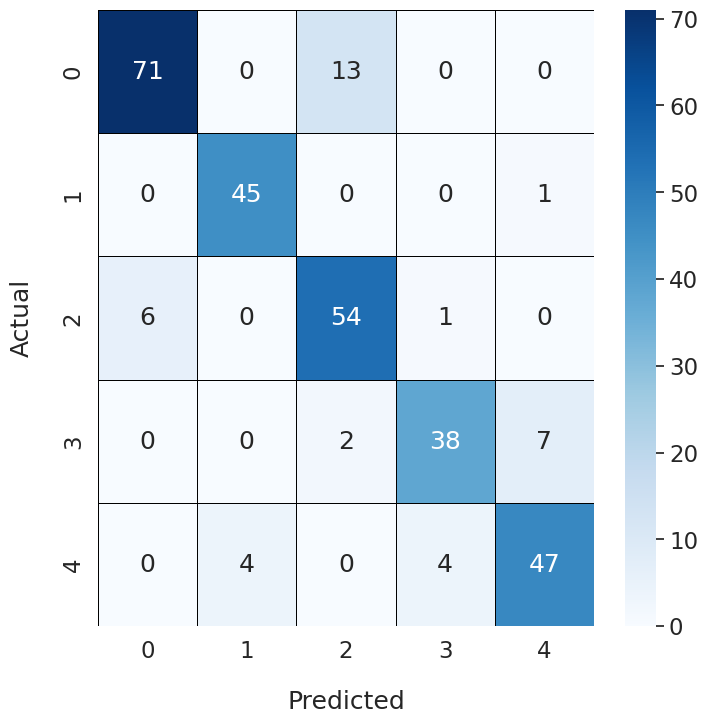

Epoch Training Time: 2772.27 seconds
Test set: Average loss: 0.4300, Accuracy: 276/323 (85.45%), F1 Score: 0.8533

Fold 5
-------
Early stopping at epoch 147 due to no improvement in validation loss.


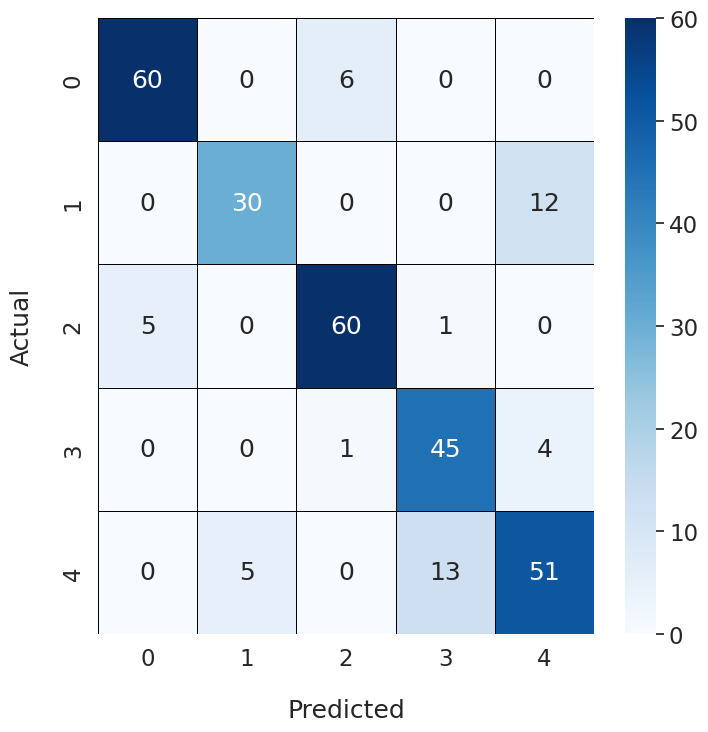

Epoch Training Time: 1922.43 seconds
Test set: Average loss: 0.4069, Accuracy: 268/323 (82.97%), F1 Score: 0.8288

Fold 6
-------
Early stopping at epoch 173 due to no improvement in validation loss.


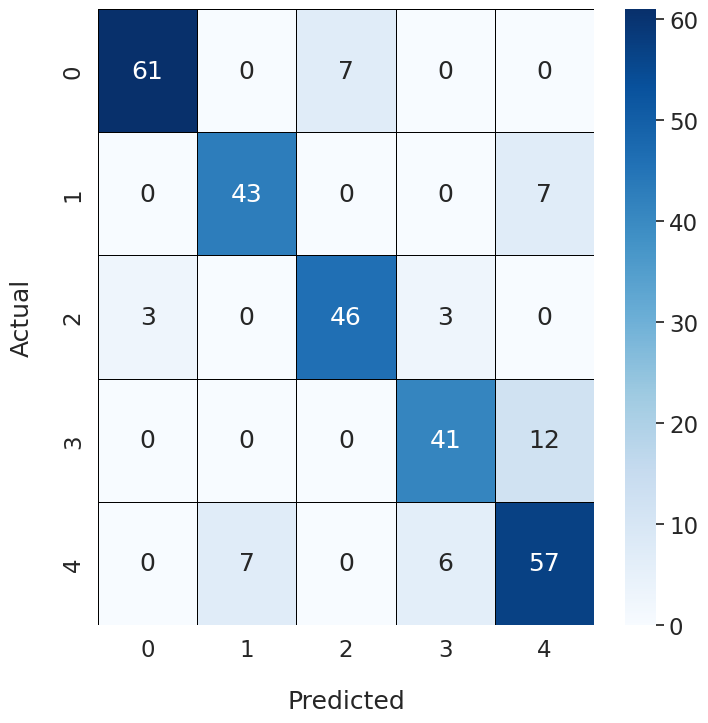

Epoch Training Time: 2263.03 seconds
Test set: Average loss: 0.3990, Accuracy: 276/323 (85.45%), F1 Score: 0.8534

Fold 7
-------
Early stopping at epoch 159 due to no improvement in validation loss.


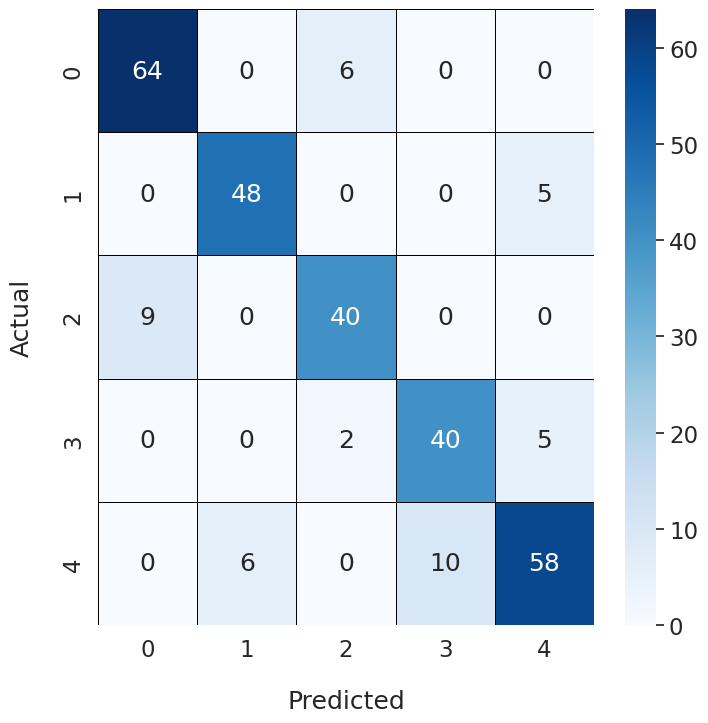

Epoch Training Time: 2079.86 seconds
Test set: Average loss: 0.4371, Accuracy: 267/323 (82.66%), F1 Score: 0.8241

Fold 8
-------
Early stopping at epoch 163 due to no improvement in validation loss.


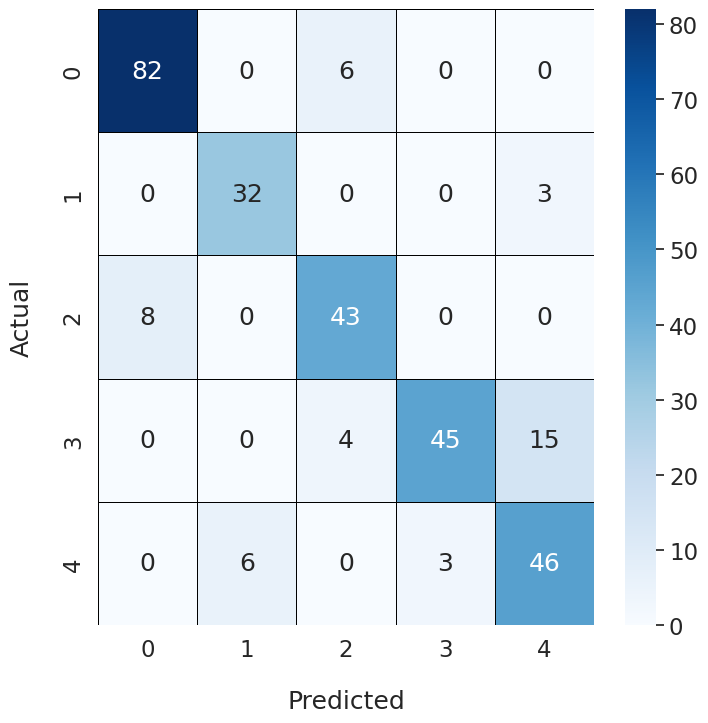

Epoch Training Time: 2133.08 seconds
Test set: Average loss: 0.3944, Accuracy: 275/323 (85.14%), F1 Score: 0.8490

Fold 9
-------
Early stopping at epoch 141 due to no improvement in validation loss.


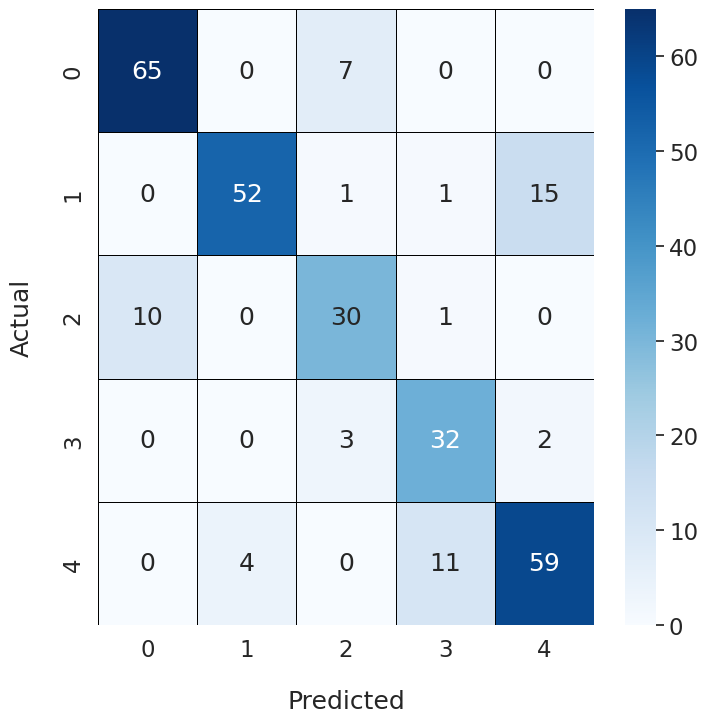

Epoch Training Time: 1844.30 seconds
Test set: Average loss: 0.4234, Accuracy: 264/323 (81.73%), F1 Score: 0.8153

Fold 10
-------
Early stopping at epoch 150 due to no improvement in validation loss.


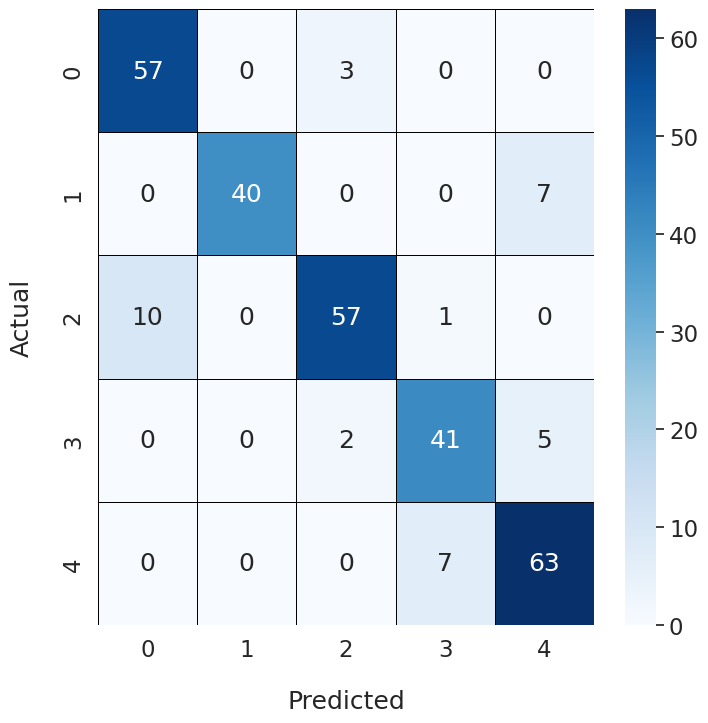

Epoch Training Time: 1965.60 seconds
Test set: Average loss: 0.3890, Accuracy: 271/323 (83.90%), F1 Score: 0.8378


Total training time for 10 folds: 21276.57 seconds


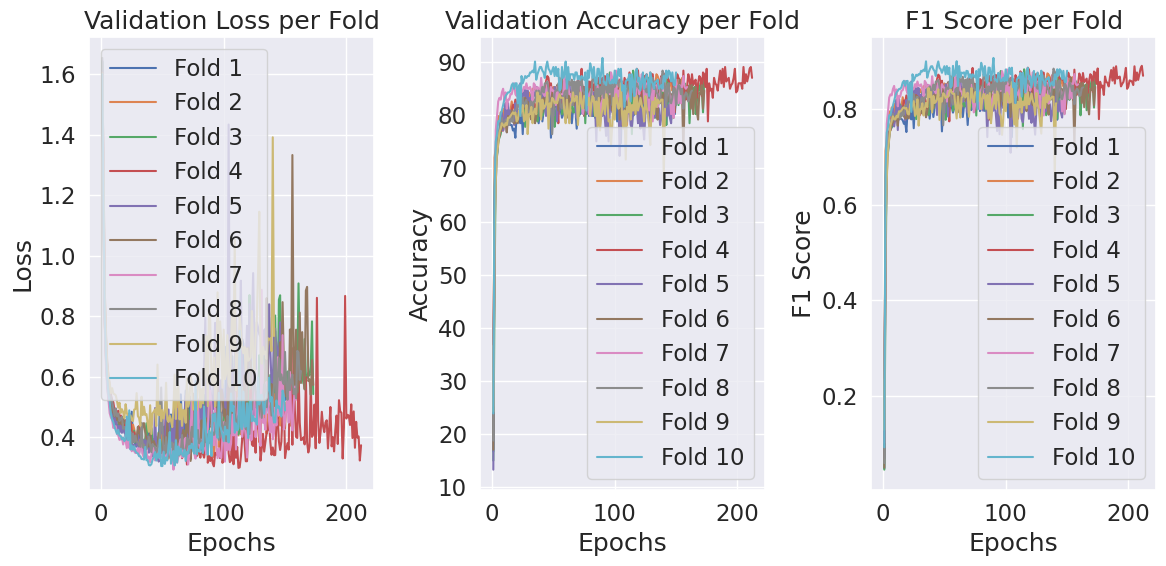

Maximum Fold Accuracy = 85.75851393188854
Maximum Fold F1 Score = 0.856617283411935
Average Fold Accuracy = 84.02476780185759
Average Fold F1 Score = 0.8385436167292765


In [23]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Darknet/SE_mix"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Darknet/SE_mix/best_SE_mix.pth"
os.makedirs("./model_Darknet/SE_mix", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_SEmix.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )

    # Initialize the model and optimizer
    model = darknet53(5).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEmix_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = darknet53(5).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [24]:
clear_all_memory()

Memory cleared and environment reset!


SE fuzzy mixed pool + Darknet---------------------------------------------------------------------------------------


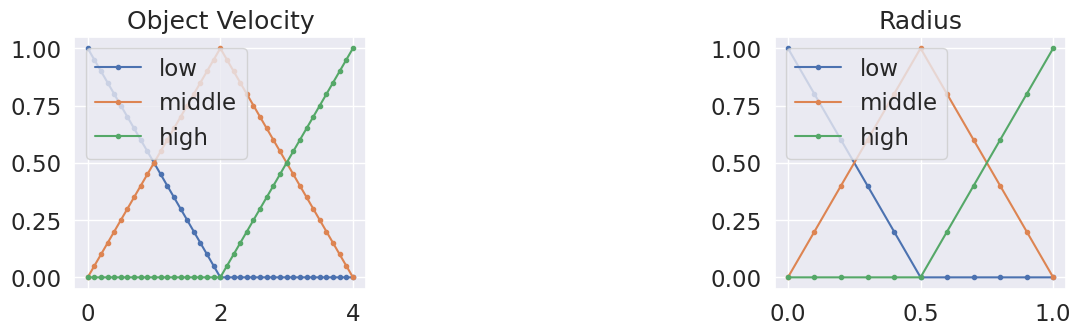

fuzzy_pool


In [25]:
from Mixedpool_fuzzy import mixedPool_fuzz

In [26]:
import import_ipynb
from starter_Darknet53 import *

In [27]:
class SE_Block_fuzz(nn.Module):
    "credits: https://github.com/moskomule/senet.pytorch/blob/master/senet/se_module.py#L4"
    def __init__(self, c, r=16):
        super().__init__()
        self.squeeze = mixedPool_fuzz()
        self.excitation = nn.Sequential(
            nn.Linear(c, c // r, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(c // r, c, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        bs, c, _, _ = x.shape
        y = self.squeeze(x).view(bs, c)
        y = self.excitation(y).view(bs, c, 1, 1)
        return x * y.expand_as(x)

In [28]:
def conv_batch(in_num, out_num, kernel_size=3, padding=1, stride=1):
    return nn.Sequential(
        nn.Conv2d(in_num, out_num, kernel_size=kernel_size, stride=stride, padding=padding, bias=False),
        nn.BatchNorm2d(out_num),
        nn.LeakyReLU())


# Residual block
class DarkResidualBlock(nn.Module):
    def __init__(self, in_channels, r=16):
        super(DarkResidualBlock, self).__init__()

        reduced_channels = int(in_channels/2)

        self.layer1 = conv_batch(in_channels, reduced_channels, kernel_size=1, padding=0)
        self.layer2 = conv_batch(reduced_channels, in_channels)
        self.se = SE_Block_fuzz(in_channels, r)

    def forward(self, x):
        residual = x

        out = self.layer1(x)
        out = self.layer2(out)

        out = self.se(out)
        
        out += residual
        return out


class Darknet53(nn.Module):
    def __init__(self, block, num_classes):
        super(Darknet53, self).__init__()

        self.num_classes = num_classes

        self.conv1 = conv_batch(3, 32)
        self.conv2 = conv_batch(32, 64, stride=2)
        self.residual_block1 = self.make_layer(block, in_channels=64, num_blocks=1)
        self.conv3 = conv_batch(64, 128, stride=2)
        self.residual_block2 = self.make_layer(block, in_channels=128, num_blocks=2)
        self.conv4 = conv_batch(128, 256, stride=2)
        self.residual_block3 = self.make_layer(block, in_channels=256, num_blocks=8)
        self.conv5 = conv_batch(256, 512, stride=2)
        self.residual_block4 = self.make_layer(block, in_channels=512, num_blocks=8)
        self.conv6 = conv_batch(512, 1024, stride=2)
        self.residual_block5 = self.make_layer(block, in_channels=1024, num_blocks=4)
        self.global_avg_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(1024, self.num_classes)

    def forward(self, x):
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.residual_block1(out)
        out = self.conv3(out)
        out = self.residual_block2(out)
        out = self.conv4(out)
        out = self.residual_block3(out)
        out = self.conv5(out)
        out = self.residual_block4(out)
        out = self.conv6(out)
        out = self.residual_block5(out)
        out = self.global_avg_pool(out)
        out = out.view(-1, 1024)
        out = self.fc(out)

        return out

    def make_layer(self, block, in_channels, num_blocks):
        layers = []
        for i in range(0, num_blocks):
            layers.append(block(in_channels))
        return nn.Sequential(*layers)


def darknet53(num_classes):
    return Darknet53(DarkResidualBlock, num_classes)

In [29]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 9.33 GMac
Model Params: 41.45 M
Early stopping at epoch 145 due to no improvement in validation loss.
Epoch Training Time: 1938.19 seconds
Test set: Average loss: 0.3945, Accuracy: 276/323 (85.45%), F1 Score: 0.8541

Fold 2
-------
Early stopping at epoch 197 due to no improvement in validation loss.
Epoch Training Time: 2635.00 seconds
Test set: Average loss: 0.3829, Accuracy: 281/323 (87.00%), F1 Score: 0.8686

Fold 3
-------
Early stopping at epoch 147 due to no improvement in validation loss.
Epoch Training Time: 1968.91 seconds
Test set: Average loss: 0.4251, Accuracy: 269/323 (83.28%), F1 Score: 0.8323

Fold 4
-------
Early stopping at epoch 206 due to no improvement in validation loss.
Epoch Training Time: 2755.35 seconds
Test set: Average loss: 0.4140, Accuracy: 277/323 (85.76%), F1 Score: 0.8566

Fold 5
-------
Early stopping at epoch 164 due to no improvement in validation loss.
Epoch Training Time: 2192.29 seconds
Test set: Average loss: 0.

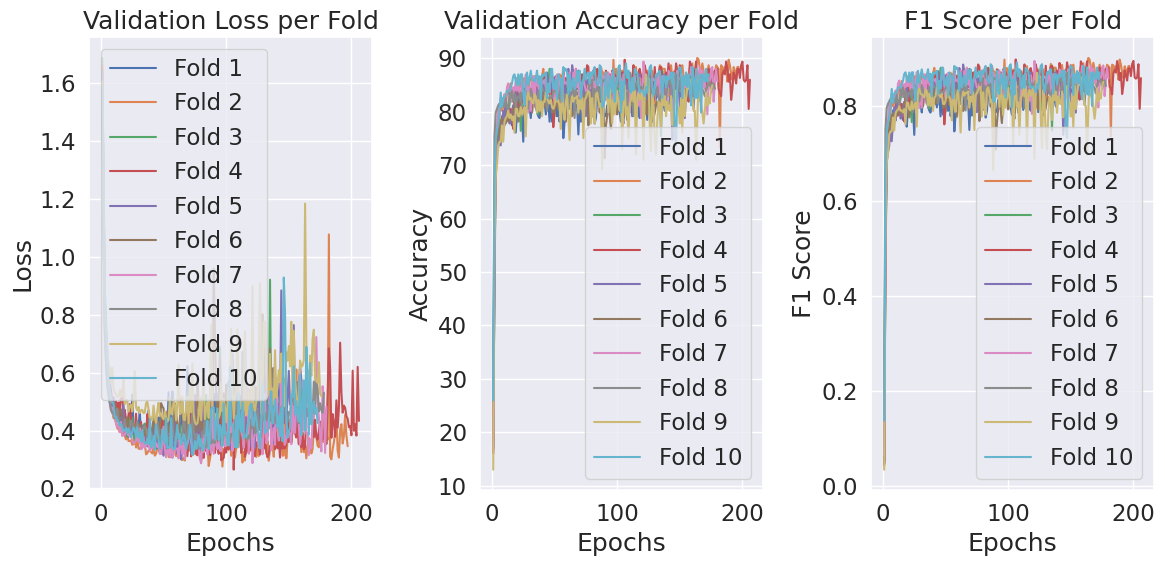

Maximum Fold Accuracy = 86.9969040247678
Maximum Fold F1 Score = 0.868594323972681
Average Fold Accuracy = 84.45820433436532
Average Fold F1 Score = 0.8429953671913554


In [30]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Darknet/SE_fuzz"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Darknet/SE_fuzz/best_SE_fuzz.pth"
os.makedirs("./model_Darknet/SE_fuzz", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_SEfuzz.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )

    # Initialize the model and optimizer
    model = darknet53(5).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
          
    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds =evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"SEfuzz_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = darknet53(5).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [31]:
clear_all_memory()

Memory cleared and environment reset!


-------------------------------------------------STAGE 2---------------------------------------------------------------

Max pool + Darknet---------------------------------------------------------------------------------------

In [32]:
import import_ipynb
from starter_Darknet53 import *

In [33]:
def conv_batch(in_num, out_num, kernel_size=3, padding=1, stride=1):
    return nn.Sequential(
        nn.Conv2d(in_num, out_num, kernel_size=kernel_size, stride=stride, padding=padding, bias=False),
        nn.BatchNorm2d(out_num),
        nn.LeakyReLU())


# Residual block
class DarkResidualBlock(nn.Module):
    def __init__(self, in_channels):
        super(DarkResidualBlock, self).__init__()

        reduced_channels = int(in_channels/2)

        self.layer1 = conv_batch(in_channels, reduced_channels, kernel_size=1, padding=0)
        self.layer2 = conv_batch(reduced_channels, in_channels)

    def forward(self, x):
        residual = x

        out = self.layer1(x)
        out = self.layer2(out)
        out += residual
        return out


class Darknet53(nn.Module):
    def __init__(self, block, num_classes):
        super(Darknet53, self).__init__()

        self.num_classes = num_classes

        self.conv1 = conv_batch(3, 32)
        self.conv2 = conv_batch(32, 64, stride=2)
        self.residual_block1 = self.make_layer(block, in_channels=64, num_blocks=1)
        self.conv3 = conv_batch(64, 128, stride=2)
        self.residual_block2 = self.make_layer(block, in_channels=128, num_blocks=2)
        self.conv4 = conv_batch(128, 256, stride=2)
        self.residual_block3 = self.make_layer(block, in_channels=256, num_blocks=8)
        self.conv5 = conv_batch(256, 512, stride=2)
        self.residual_block4 = self.make_layer(block, in_channels=512, num_blocks=8)
        self.conv6 = conv_batch(512, 1024, stride=2)
        self.residual_block5 = self.make_layer(block, in_channels=1024, num_blocks=4)
        self.max_pool = nn.AdaptiveMaxPool2d((1, 1))
        self.fc = nn.Linear(1024, self.num_classes)

    def forward(self, x):
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.residual_block1(out)
        out = self.conv3(out)
        out = self.residual_block2(out)
        out = self.conv4(out)
        out = self.residual_block3(out)
        out = self.conv5(out)
        out = self.residual_block4(out)
        out = self.conv6(out)
        out = self.residual_block5(out)
        out = self.max_pool(out)
        out = out.view(-1, 1024)
        out = self.fc(out)

        return out

    def make_layer(self, block, in_channels, num_blocks):
        layers = []
        for i in range(0, num_blocks):
            layers.append(block(in_channels))
        return nn.Sequential(*layers)


def darknet53(num_classes):
    return Darknet53(DarkResidualBlock, num_classes)

In [34]:
all_folds_val_loss = []
all_folds_val_acc = []
all_folds_f1 = []
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 9.32 GMac
Model Params: 40.59 M
Early stopping at epoch 124 due to no improvement in validation loss.


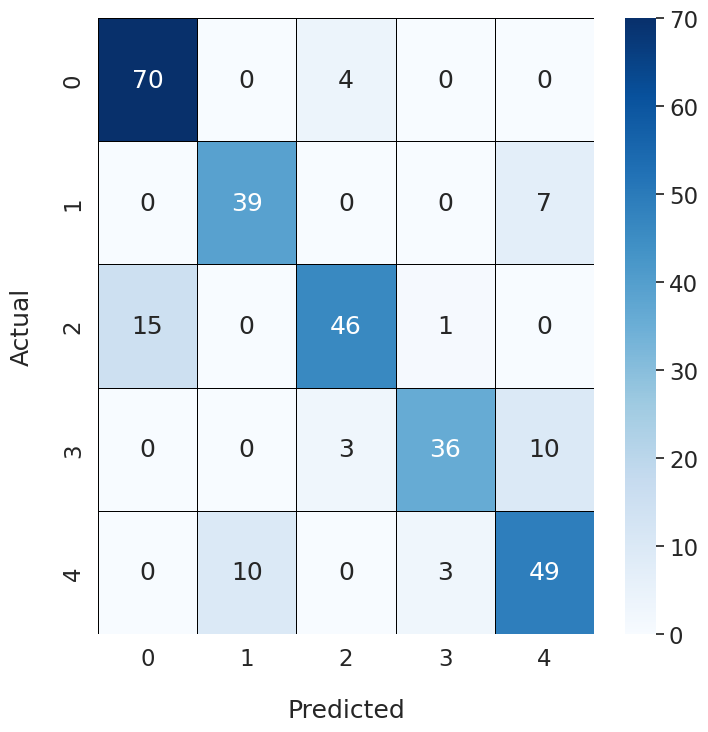

Epoch Training Time: 1306.80 seconds
Test set: Average loss: 0.4244, Accuracy: 268/323 (82.97%), F1 Score: 0.8275

Fold 2
-------
Early stopping at epoch 182 due to no improvement in validation loss.


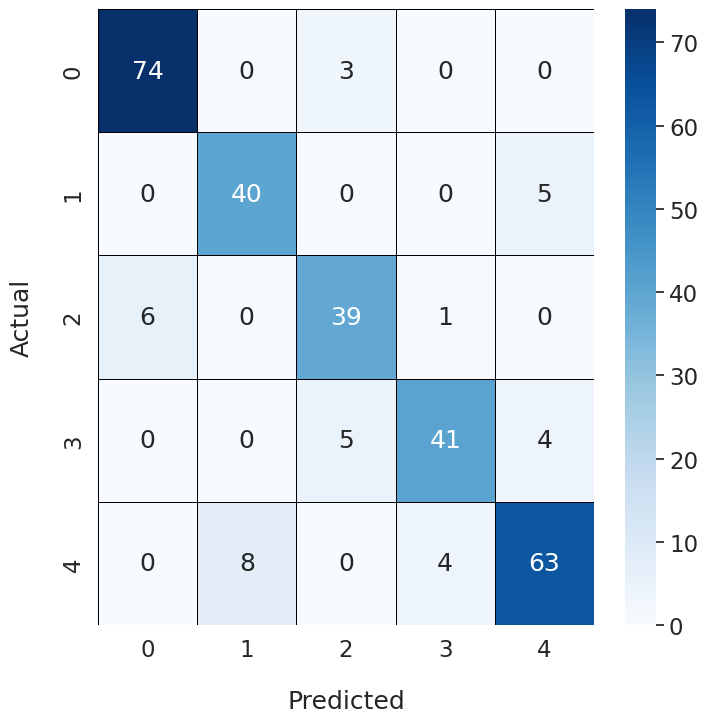

Epoch Training Time: 1918.36 seconds
Test set: Average loss: 0.4651, Accuracy: 272/323 (84.21%), F1 Score: 0.8400

Fold 3
-------
Early stopping at epoch 138 due to no improvement in validation loss.


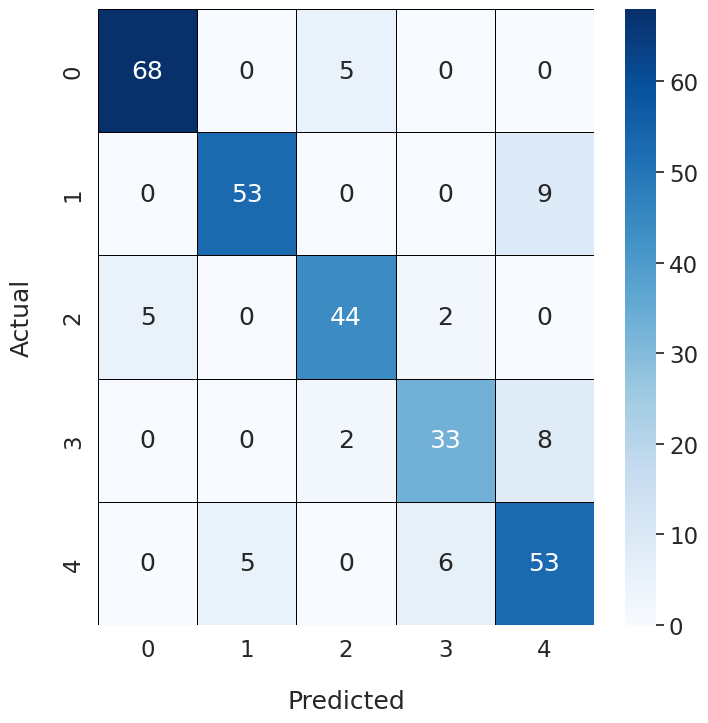

Epoch Training Time: 1453.15 seconds
Test set: Average loss: 0.4682, Accuracy: 265/323 (82.04%), F1 Score: 0.8175

Fold 4
-------
Early stopping at epoch 144 due to no improvement in validation loss.


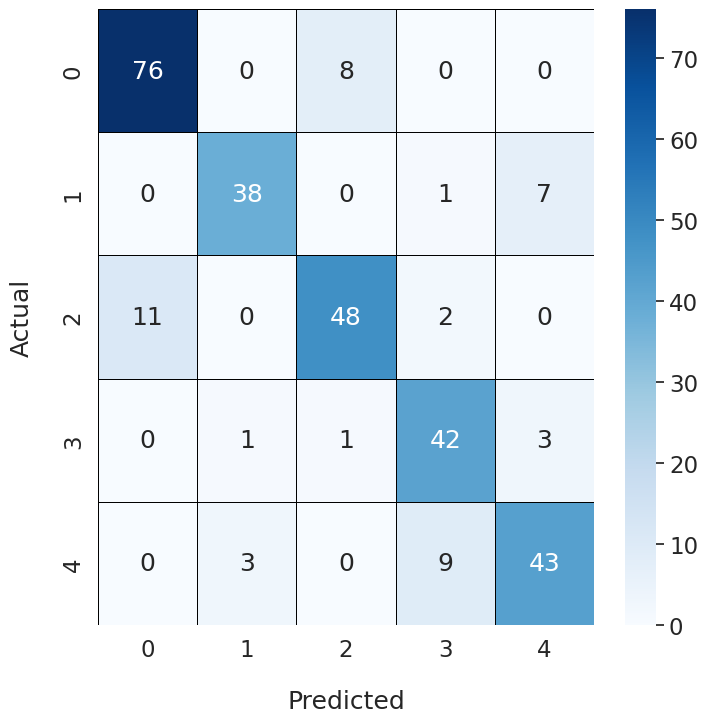

Epoch Training Time: 1518.50 seconds
Test set: Average loss: 0.4474, Accuracy: 269/323 (83.28%), F1 Score: 0.8292

Fold 5
-------
Early stopping at epoch 144 due to no improvement in validation loss.


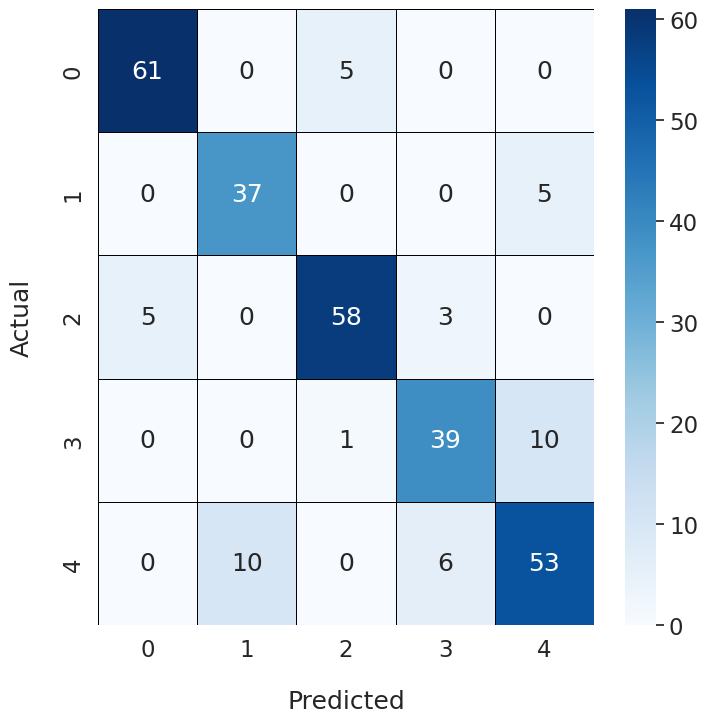

Epoch Training Time: 1516.38 seconds
Test set: Average loss: 0.4737, Accuracy: 266/323 (82.35%), F1 Score: 0.8202

Fold 6
-------
Early stopping at epoch 157 due to no improvement in validation loss.


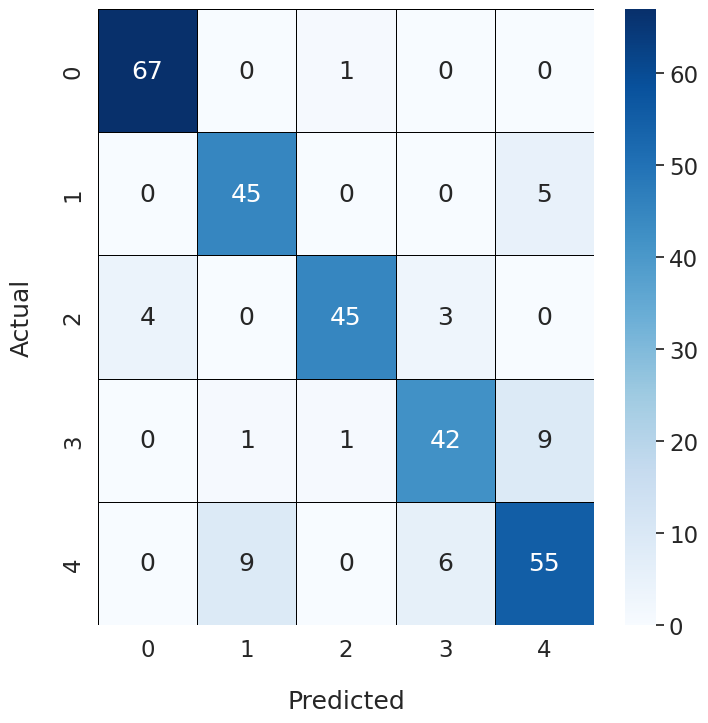

Epoch Training Time: 1653.21 seconds
Test set: Average loss: 0.4263, Accuracy: 273/323 (84.52%), F1 Score: 0.8441

Fold 7
-------
Early stopping at epoch 153 due to no improvement in validation loss.


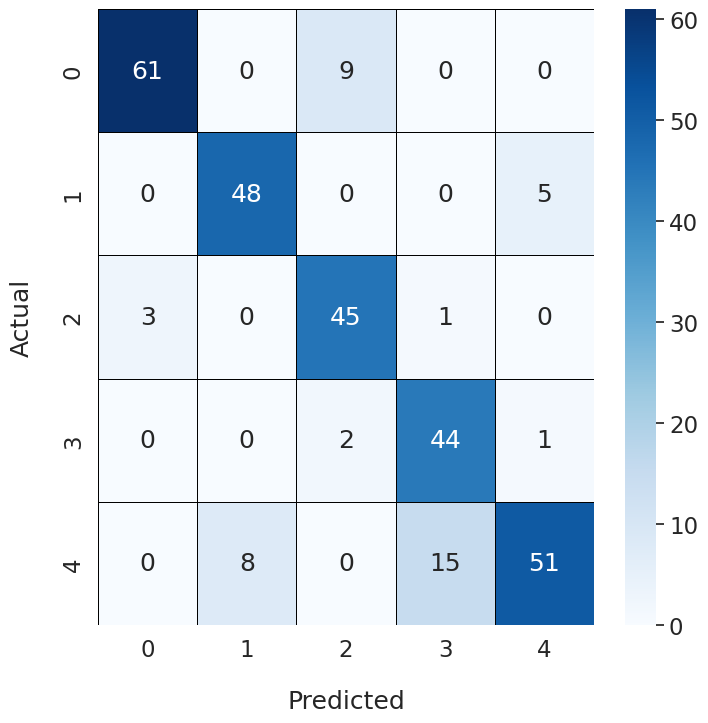

Epoch Training Time: 1614.15 seconds
Test set: Average loss: 0.4736, Accuracy: 264/323 (81.73%), F1 Score: 0.8146

Fold 8
-------
Early stopping at epoch 121 due to no improvement in validation loss.


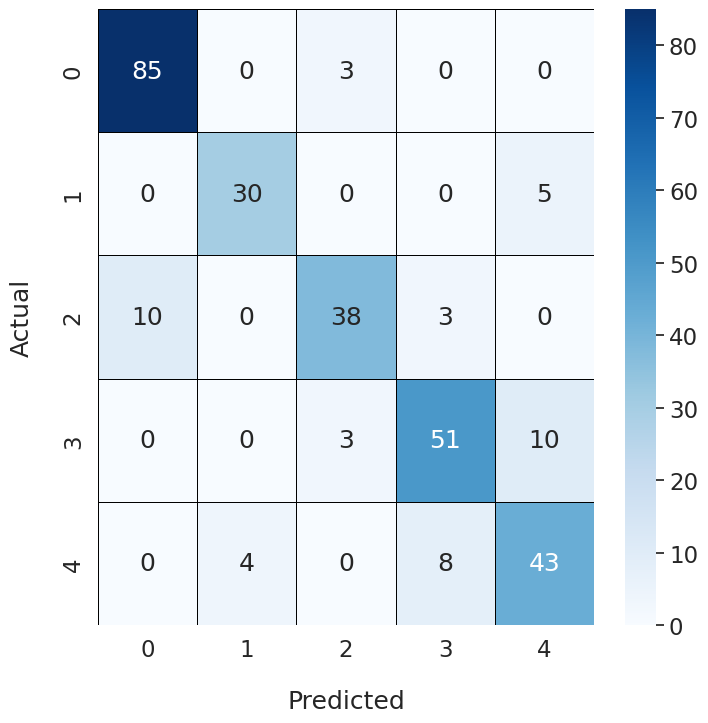

Epoch Training Time: 1273.91 seconds
Test set: Average loss: 0.4309, Accuracy: 272/323 (84.21%), F1 Score: 0.8399

Fold 9
-------
Early stopping at epoch 131 due to no improvement in validation loss.


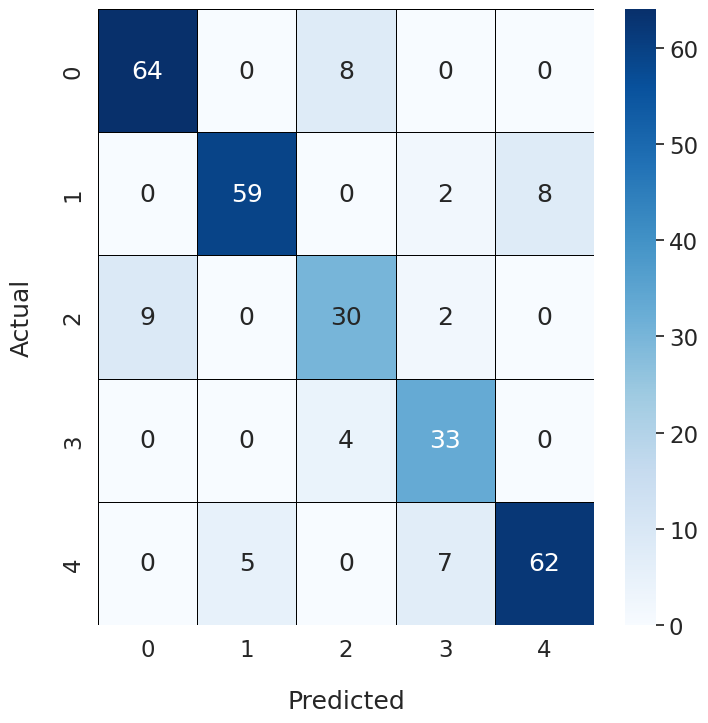

Epoch Training Time: 1379.66 seconds
Test set: Average loss: 0.4294, Accuracy: 273/323 (84.52%), F1 Score: 0.8428

Fold 10
-------
Early stopping at epoch 143 due to no improvement in validation loss.


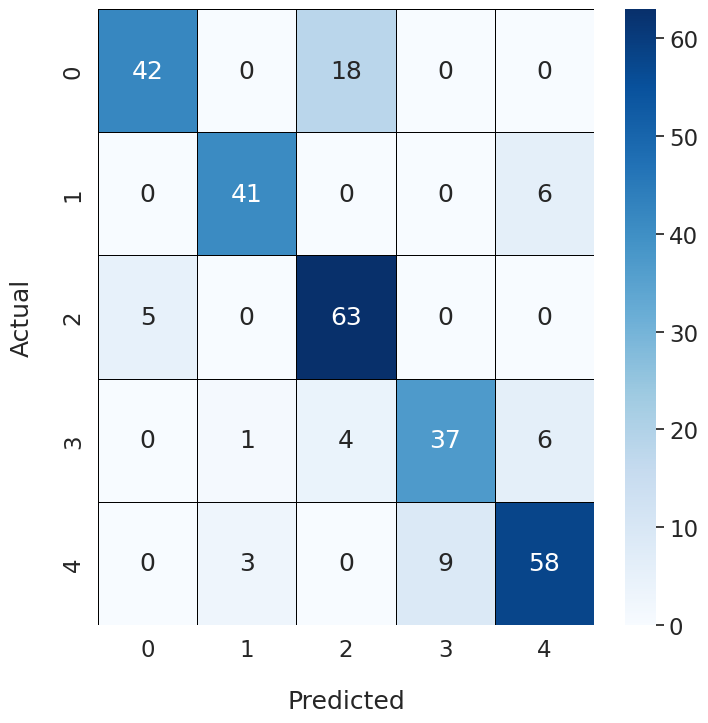

Epoch Training Time: 1507.13 seconds
Test set: Average loss: 0.3870, Accuracy: 268/323 (82.97%), F1 Score: 0.8269


Total training time for 10 folds: 15141.25 seconds


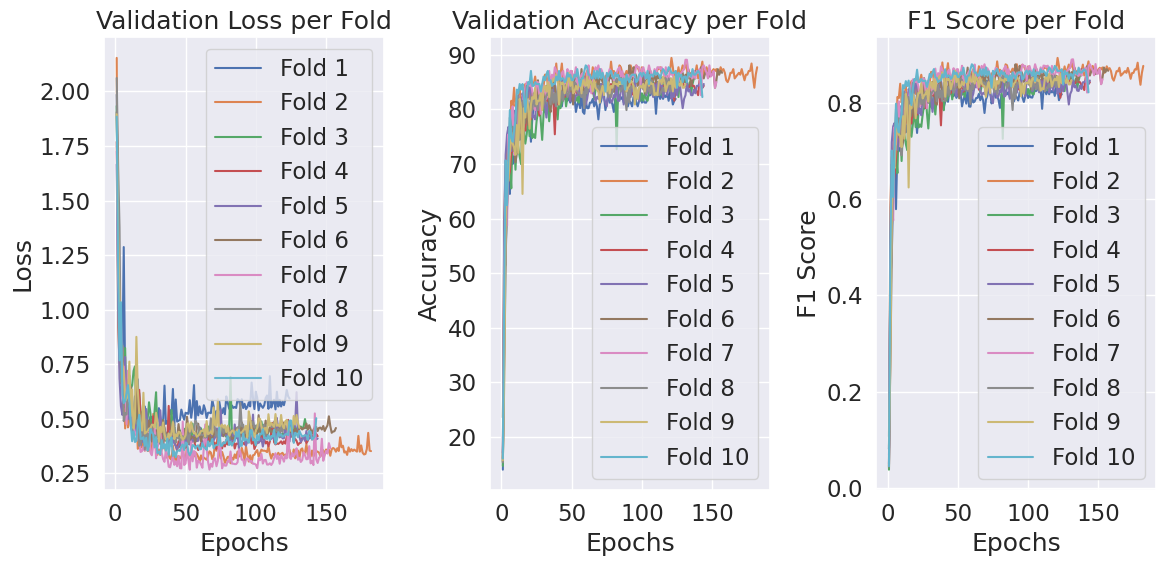

Maximum Fold Accuracy = 84.52012383900929
Maximum Fold F1 Score = 0.8441016364111669
Average Fold Accuracy = 83.28173374613003
Average Fold F1 Score = 0.8302801515900381


In [35]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Darknet/darkmax"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Darknet/darkmax/darkmax.pth"
os.makedirs("./model_Darknet/darkmax", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_darkmax.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []

   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )
    # Initialize the model and optimizer
    model = darknet53(5).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1

    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop
                
    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")
    
    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"darkmax_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])

    all_folds_val_loss.append(epoch_val_loss.copy())
    all_folds_val_acc.append(epoch_val_acc.copy())
    all_folds_f1.append(epochs_f1_score.copy())

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = darknet53(5).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [36]:
clear_all_memory()

Memory cleared and environment reset!


Mixed pool + Darknet---------------------------------------------------------------------------------------

In [37]:
from Mixedpool05 import mixedPool

In [38]:
import import_ipynb
from starter_Darknet53 import *

In [39]:
def conv_batch(in_num, out_num, kernel_size=3, padding=1, stride=1):
    return nn.Sequential(
        nn.Conv2d(in_num, out_num, kernel_size=kernel_size, stride=stride, padding=padding, bias=False),
        nn.BatchNorm2d(out_num),
        nn.LeakyReLU())


# Residual block
class DarkResidualBlock(nn.Module):
    def __init__(self, in_channels, r=16):
        super(DarkResidualBlock, self).__init__()

        reduced_channels = int(in_channels/2)

        self.layer1 = conv_batch(in_channels, reduced_channels, kernel_size=1, padding=0)
        self.layer2 = conv_batch(reduced_channels, in_channels)

    def forward(self, x):
        residual = x

        out = self.layer1(x)
        out = self.layer2(out)
        
        out += residual
        return out


class Darknet53(nn.Module):
    def __init__(self, block, num_classes):
        super(Darknet53, self).__init__()

        self.num_classes = num_classes

        self.conv1 = conv_batch(3, 32)
        self.conv2 = conv_batch(32, 64, stride=2)
        self.residual_block1 = self.make_layer(block, in_channels=64, num_blocks=1)
        self.conv3 = conv_batch(64, 128, stride=2)
        self.residual_block2 = self.make_layer(block, in_channels=128, num_blocks=2)
        self.conv4 = conv_batch(128, 256, stride=2)
        self.residual_block3 = self.make_layer(block, in_channels=256, num_blocks=8)
        self.conv5 = conv_batch(256, 512, stride=2)
        self.residual_block4 = self.make_layer(block, in_channels=512, num_blocks=8)
        self.conv6 = conv_batch(512, 1024, stride=2)
        self.residual_block5 = self.make_layer(block, in_channels=1024, num_blocks=4)
        self.mixedpool = mixedPool()
        self.fc = nn.Linear(1024, self.num_classes)

    def forward(self, x):
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.residual_block1(out)
        out = self.conv3(out)
        out = self.residual_block2(out)
        out = self.conv4(out)
        out = self.residual_block3(out)
        out = self.conv5(out)
        out = self.residual_block4(out)
        out = self.conv6(out)
        out = self.residual_block5(out)
        out = self.mixedpool(out)
        out = out.view(-1, 1024)
        out = self.fc(out)

        return out

    def make_layer(self, block, in_channels, num_blocks):
        layers = []
        for i in range(0, num_blocks):
            layers.append(block(in_channels))
        return nn.Sequential(*layers)


def darknet53(num_classes):
    return Darknet53(DarkResidualBlock, num_classes)

In [40]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 9.32 GMac
Model Params: 40.59 M
Early stopping at epoch 145 due to no improvement in validation loss.


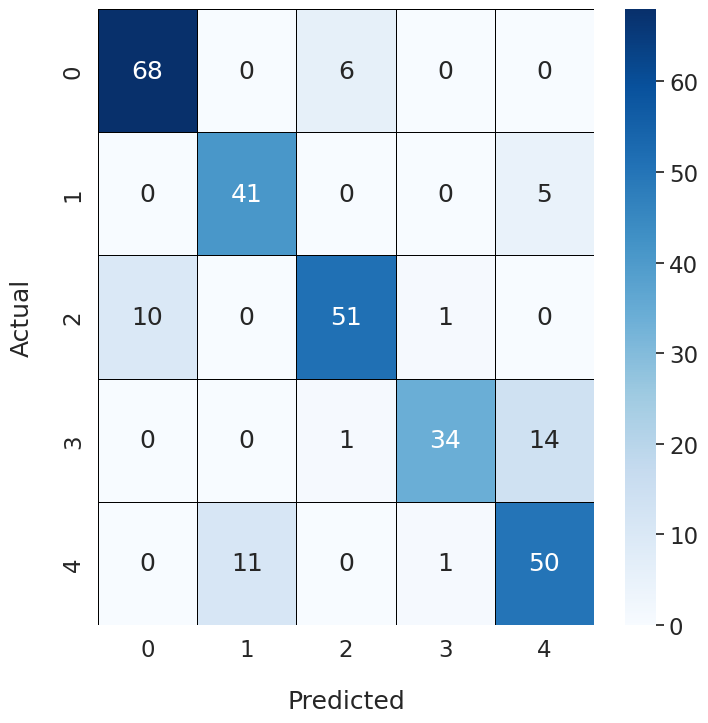

Epoch Training Time: 1529.30 seconds
Test set: Average loss: 0.3799, Accuracy: 282/323 (87.31%), F1 Score: 0.8722

Fold 2
-------
Early stopping at epoch 148 due to no improvement in validation loss.


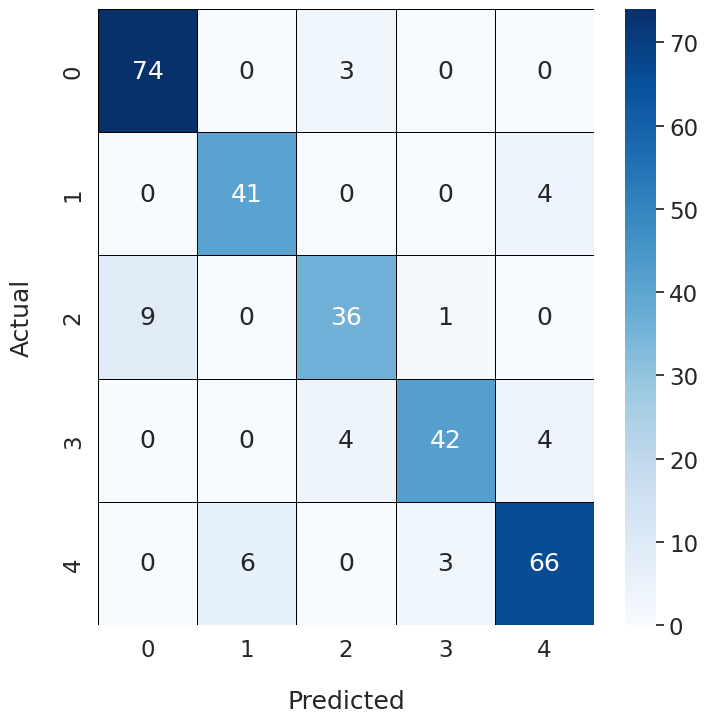

Epoch Training Time: 1562.22 seconds
Test set: Average loss: 0.3623, Accuracy: 277/323 (85.76%), F1 Score: 0.8570

Fold 3
-------
Early stopping at epoch 153 due to no improvement in validation loss.


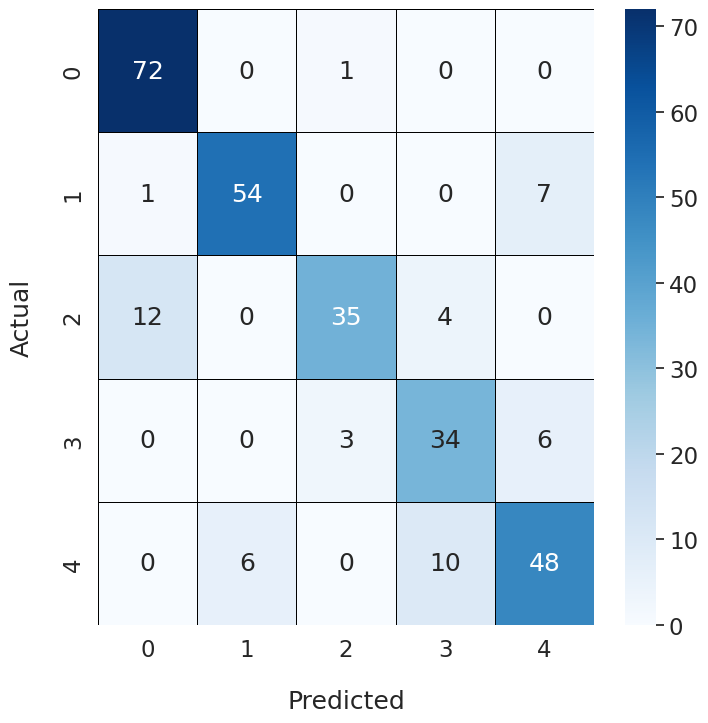

Epoch Training Time: 1616.92 seconds
Test set: Average loss: 0.4248, Accuracy: 278/323 (86.07%), F1 Score: 0.8595

Fold 4
-------
Early stopping at epoch 135 due to no improvement in validation loss.


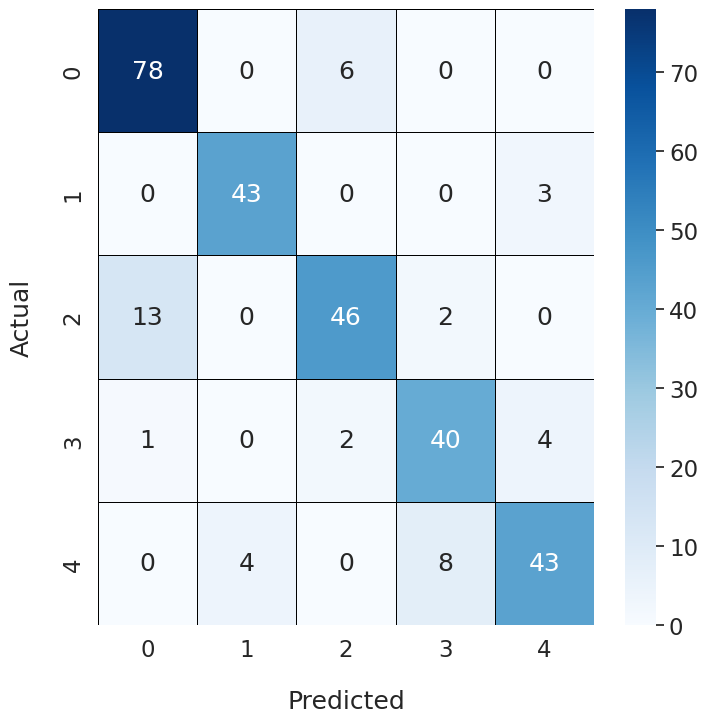

Epoch Training Time: 1424.99 seconds
Test set: Average loss: 0.4223, Accuracy: 277/323 (85.76%), F1 Score: 0.8561

Fold 5
-------
Early stopping at epoch 137 due to no improvement in validation loss.


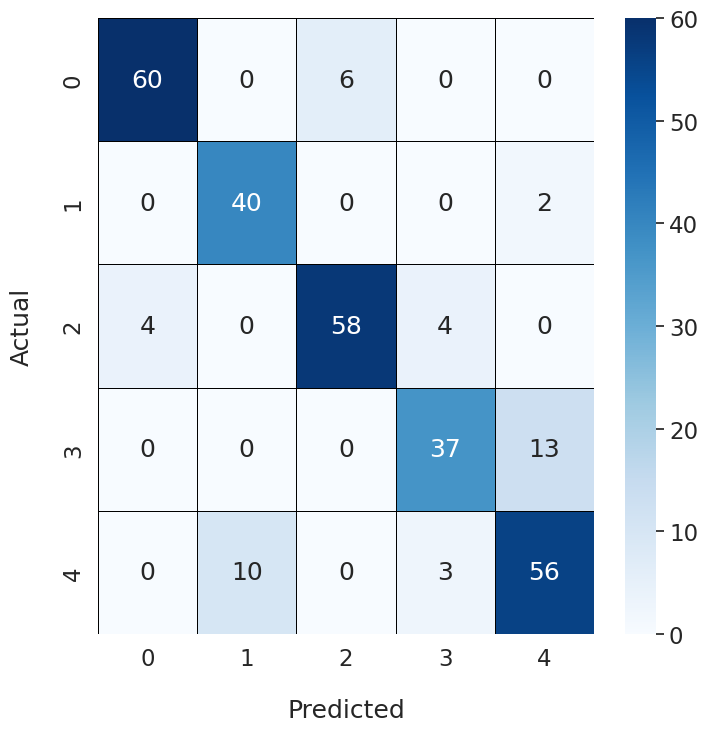

Epoch Training Time: 1446.88 seconds
Test set: Average loss: 0.4160, Accuracy: 275/323 (85.14%), F1 Score: 0.8504

Fold 6
-------
Early stopping at epoch 183 due to no improvement in validation loss.


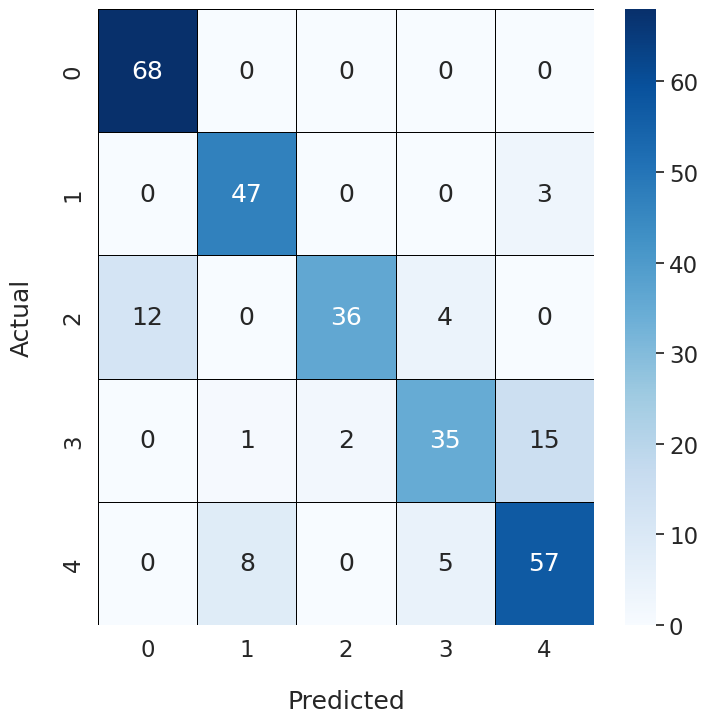

Epoch Training Time: 1932.24 seconds
Test set: Average loss: 0.4722, Accuracy: 279/323 (86.38%), F1 Score: 0.8624

Fold 7
-------
Early stopping at epoch 180 due to no improvement in validation loss.


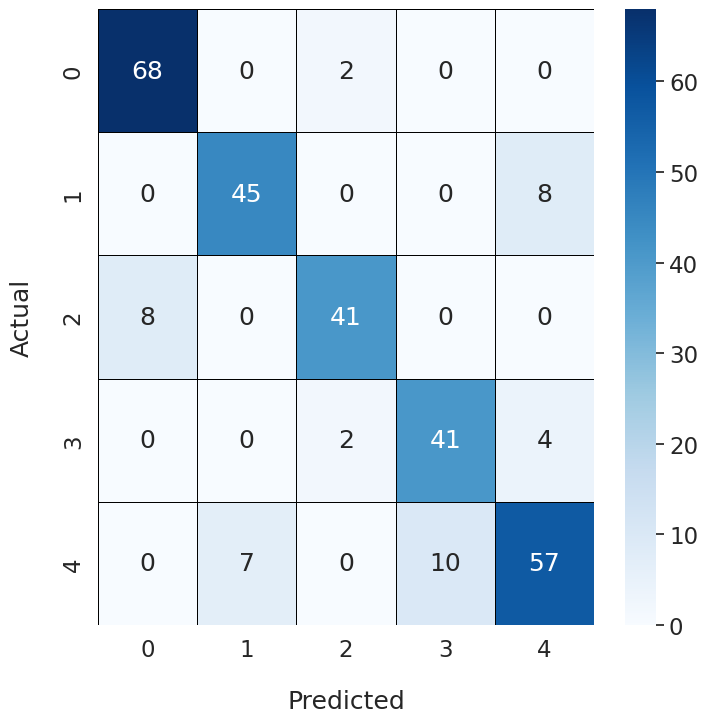

Epoch Training Time: 1902.52 seconds
Test set: Average loss: 0.4627, Accuracy: 267/323 (82.66%), F1 Score: 0.8250

Fold 8
-------
Early stopping at epoch 132 due to no improvement in validation loss.


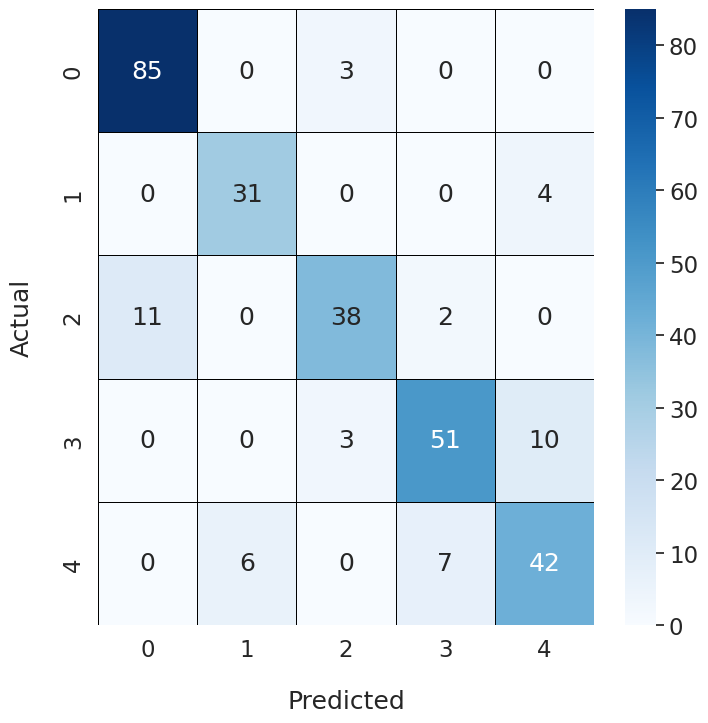

Epoch Training Time: 1395.40 seconds
Test set: Average loss: 0.4387, Accuracy: 269/323 (83.28%), F1 Score: 0.8305

Fold 9
-------
Early stopping at epoch 146 due to no improvement in validation loss.


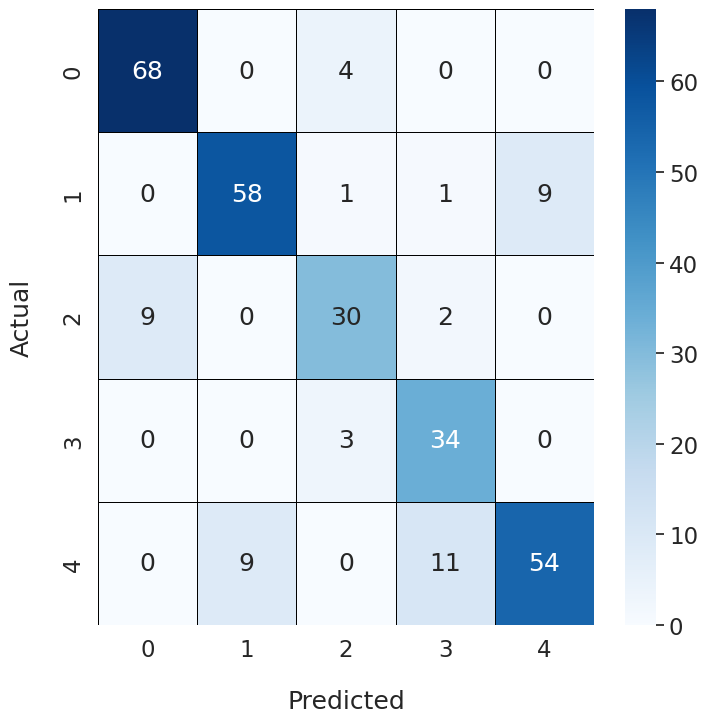

Epoch Training Time: 1542.06 seconds
Test set: Average loss: 0.4088, Accuracy: 277/323 (85.76%), F1 Score: 0.8560

Fold 10
-------
Early stopping at epoch 135 due to no improvement in validation loss.


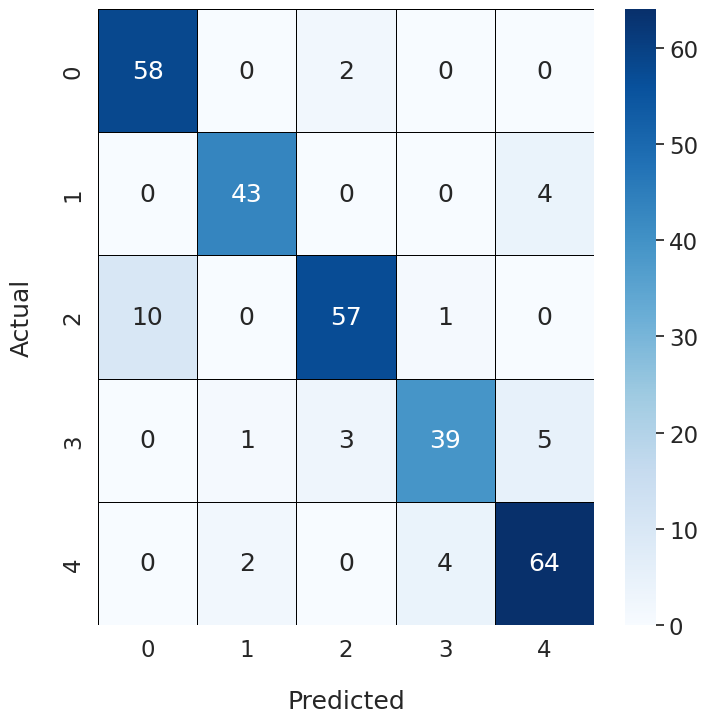

Epoch Training Time: 1427.43 seconds
Test set: Average loss: 0.4379, Accuracy: 268/323 (82.97%), F1 Score: 0.8278


Total training time for 10 folds: 15779.94 seconds


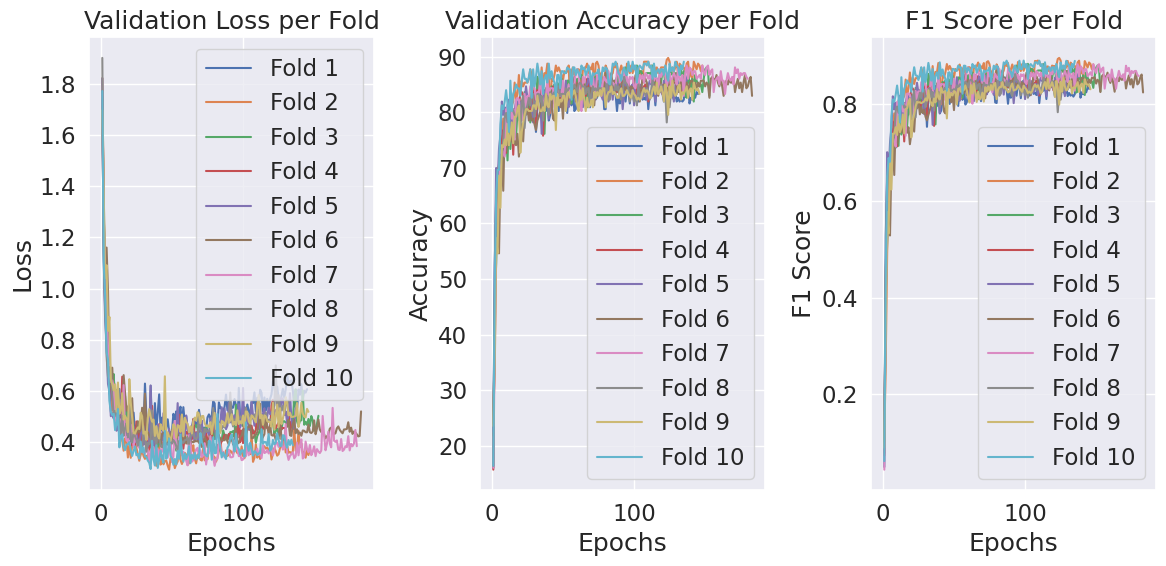

Maximum Fold Accuracy = 87.30650154798762
Maximum Fold F1 Score = 0.8721780095889102
Average Fold Accuracy = 85.10835913312692
Average Fold F1 Score = 0.8496864501554098


In [41]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Darknet/dark_mix"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Darknet/dark_mix/dark_mix.pth"
os.makedirs("./model_Darknet/dark_mix", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_dark_mix.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []


   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )

    # Initialize the model and optimizer
    model = darknet53(5).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1
    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop

    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")

    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"dark_mix_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])
    
    all_folds_val_loss.append(epoch_val_loss.copy()) #-------------
    all_folds_val_acc.append(epoch_val_acc.copy()) #-------------
    all_folds_f1.append(epochs_f1_score.copy()) #-------------

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = darknet53(5).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [42]:
clear_all_memory()

Memory cleared and environment reset!


Fuzzy mixed pool + Darknet---------------------------------------------------------------------------------------

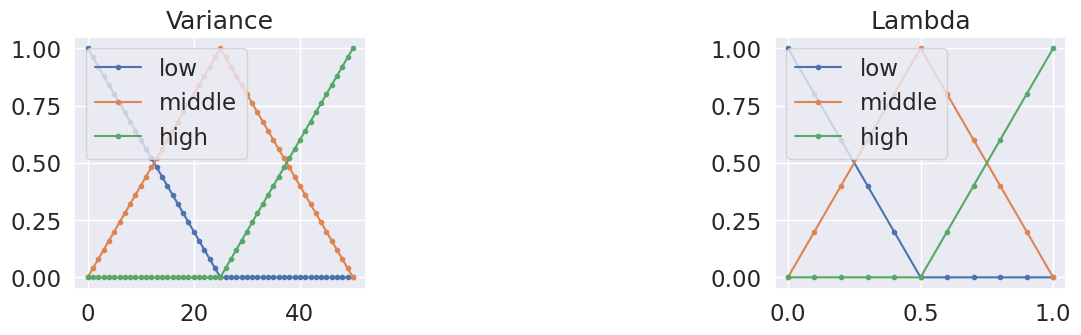

fuzzy_pool_noSE


In [43]:
from Mixedpool_fuzzy_noSE import mixedPool_fuzz

In [44]:
import import_ipynb
from starter_Darknet53 import *

In [45]:
def conv_batch(in_num, out_num, kernel_size=3, padding=1, stride=1):
    return nn.Sequential(
        nn.Conv2d(in_num, out_num, kernel_size=kernel_size, stride=stride, padding=padding, bias=False),
        nn.BatchNorm2d(out_num),
        nn.LeakyReLU())


# Residual block
class DarkResidualBlock(nn.Module):
    def __init__(self, in_channels):
        super(DarkResidualBlock, self).__init__()

        reduced_channels = int(in_channels/2)

        self.layer1 = conv_batch(in_channels, reduced_channels, kernel_size=1, padding=0)
        self.layer2 = conv_batch(reduced_channels, in_channels)

    def forward(self, x):
        residual = x

        out = self.layer1(x)
        out = self.layer2(out)
        out += residual
        return out


class Darknet53(nn.Module):
    def __init__(self, block, num_classes):
        super(Darknet53, self).__init__()

        self.num_classes = num_classes

        self.conv1 = conv_batch(3, 32)
        self.conv2 = conv_batch(32, 64, stride=2)
        self.residual_block1 = self.make_layer(block, in_channels=64, num_blocks=1)
        self.conv3 = conv_batch(64, 128, stride=2)
        self.residual_block2 = self.make_layer(block, in_channels=128, num_blocks=2)
        self.conv4 = conv_batch(128, 256, stride=2)
        self.residual_block3 = self.make_layer(block, in_channels=256, num_blocks=8)
        self.conv5 = conv_batch(256, 512, stride=2)
        self.residual_block4 = self.make_layer(block, in_channels=512, num_blocks=8)
        self.conv6 = conv_batch(512, 1024, stride=2)
        self.residual_block5 = self.make_layer(block, in_channels=1024, num_blocks=4)
        self.fuzzy_pool = mixedPool_fuzz()
        self.fc = nn.Linear(1024, self.num_classes)

    def forward(self, x):
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.residual_block1(out)
        out = self.conv3(out)
        out = self.residual_block2(out)
        out = self.conv4(out)
        out = self.residual_block3(out)
        out = self.conv5(out)
        out = self.residual_block4(out)
        out = self.conv6(out)
        out = self.residual_block5(out)
        out = self.fuzzy_pool(out)
        out = out.view(-1, 1024)
        out = self.fc(out)

        return out

    def make_layer(self, block, in_channels, num_blocks):
        layers = []
        for i in range(0, num_blocks):
            layers.append(block(in_channels))
        return nn.Sequential(*layers)


def darknet53(num_classes):
    return Darknet53(DarkResidualBlock, num_classes)

In [46]:
all_folds_val_loss = [] #-------------
all_folds_val_acc = [] #-------------
all_folds_f1 = [] #-------------
all_fold_time = []

patience = 100
epochs_no_improve = 0

Fold 1
-------
Model FLOPs (MACs): 9.32 GMac
Model Params: 40.59 M
Early stopping at epoch 154 due to no improvement in validation loss.


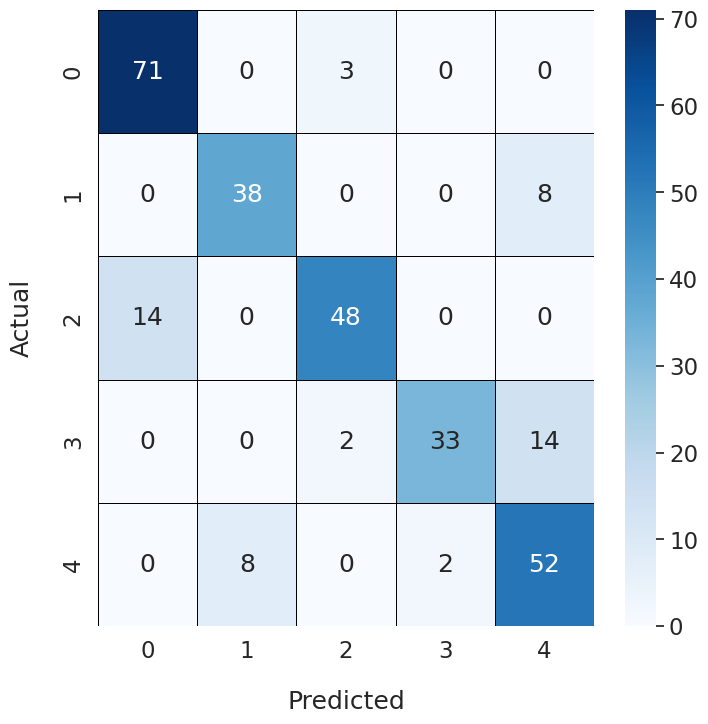

Epoch Training Time: 1632.80 seconds
Test set: Average loss: 0.4163, Accuracy: 274/323 (84.83%), F1 Score: 0.8467

Fold 2
-------
Early stopping at epoch 163 due to no improvement in validation loss.


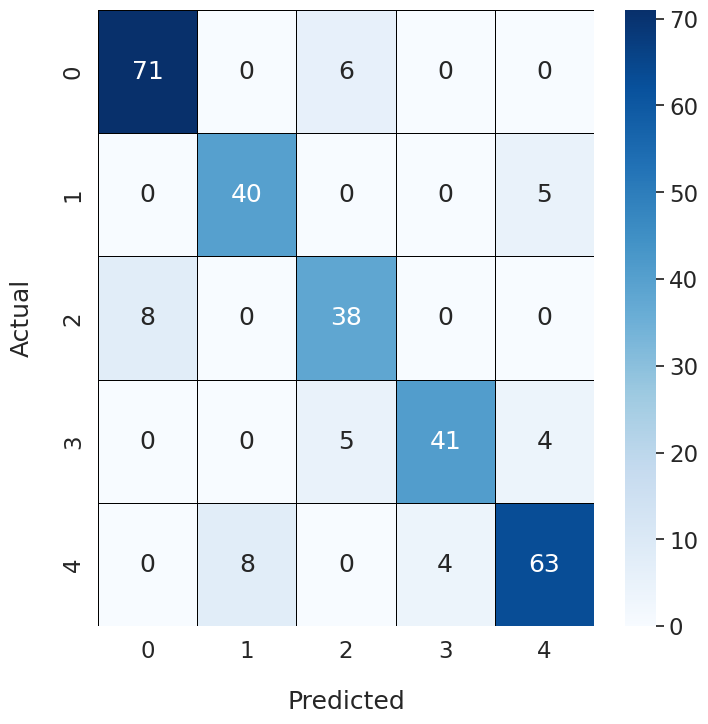

Epoch Training Time: 1728.37 seconds
Test set: Average loss: 0.4370, Accuracy: 271/323 (83.90%), F1 Score: 0.8384

Fold 3
-------
Early stopping at epoch 161 due to no improvement in validation loss.


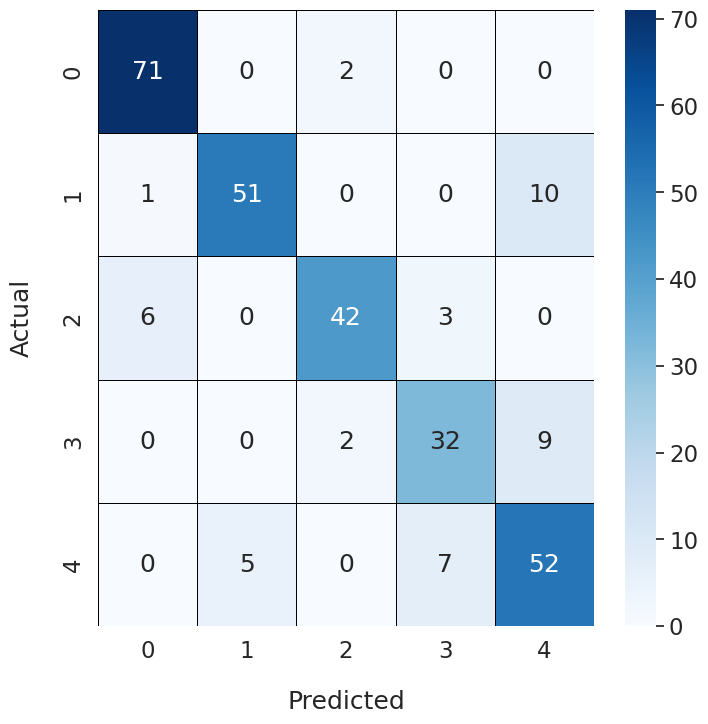

Epoch Training Time: 1707.84 seconds
Test set: Average loss: 0.3968, Accuracy: 275/323 (85.14%), F1 Score: 0.8507

Fold 4
-------
Early stopping at epoch 290 due to no improvement in validation loss.


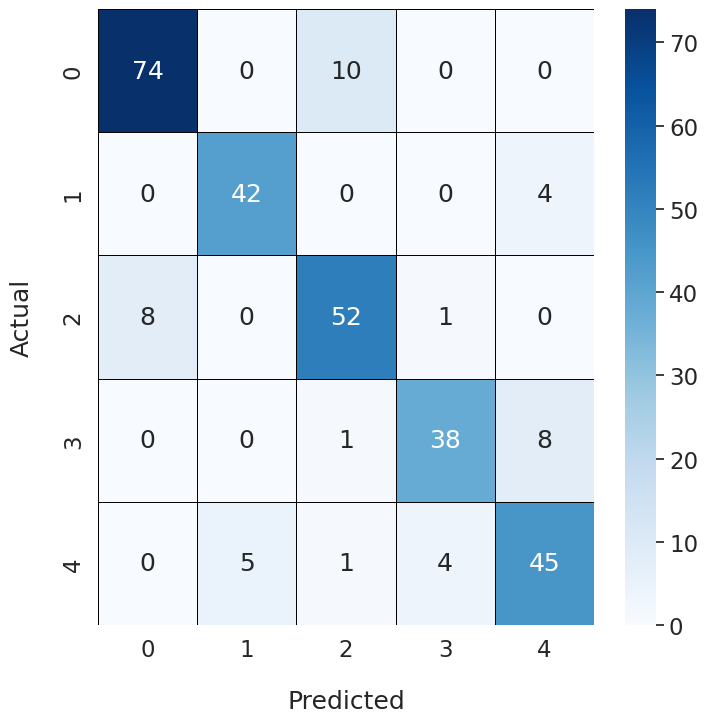

Epoch Training Time: 3072.95 seconds
Test set: Average loss: 0.6366, Accuracy: 270/323 (83.59%), F1 Score: 0.8350

Fold 5
-------
Early stopping at epoch 154 due to no improvement in validation loss.


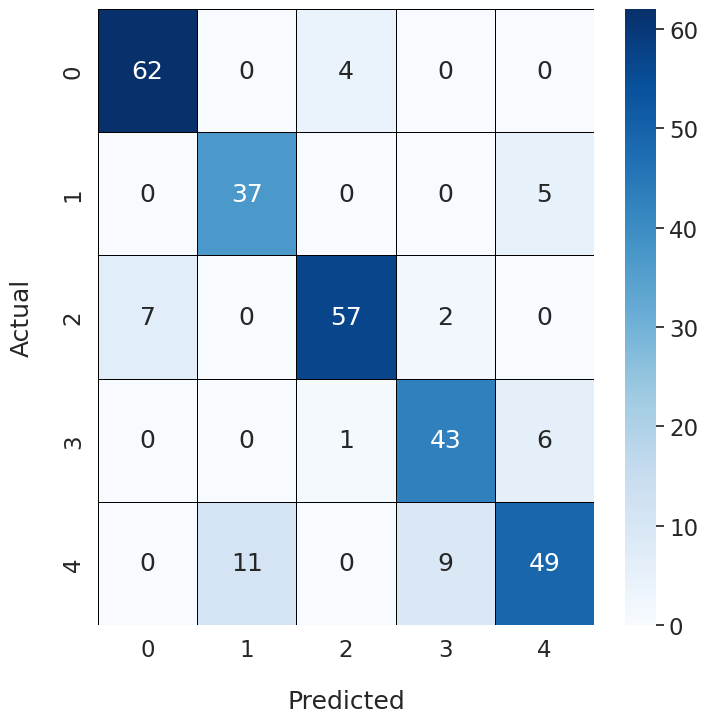

Epoch Training Time: 1632.29 seconds
Test set: Average loss: 0.4402, Accuracy: 269/323 (83.28%), F1 Score: 0.8320

Fold 6
-------
Early stopping at epoch 195 due to no improvement in validation loss.


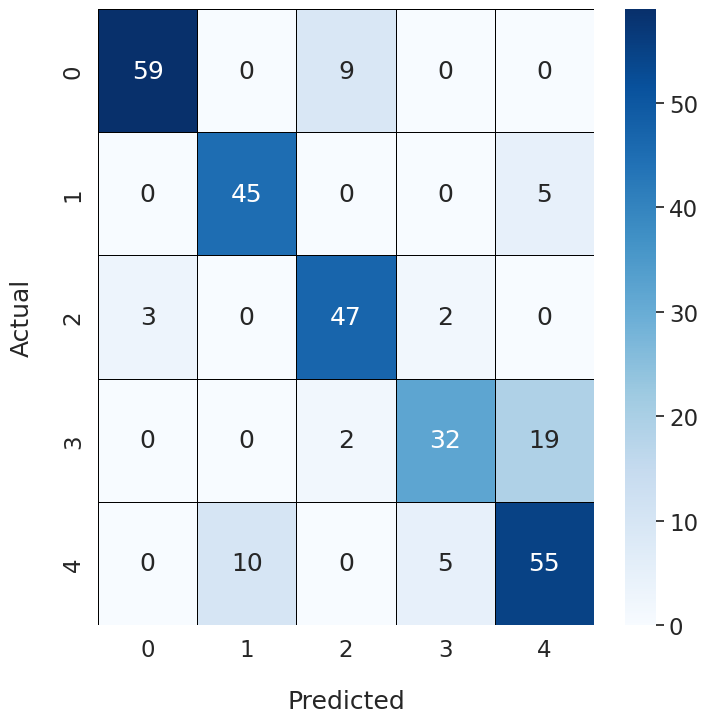

Epoch Training Time: 2065.24 seconds
Test set: Average loss: 0.4519, Accuracy: 278/323 (86.07%), F1 Score: 0.8596

Fold 7
-------
Early stopping at epoch 209 due to no improvement in validation loss.


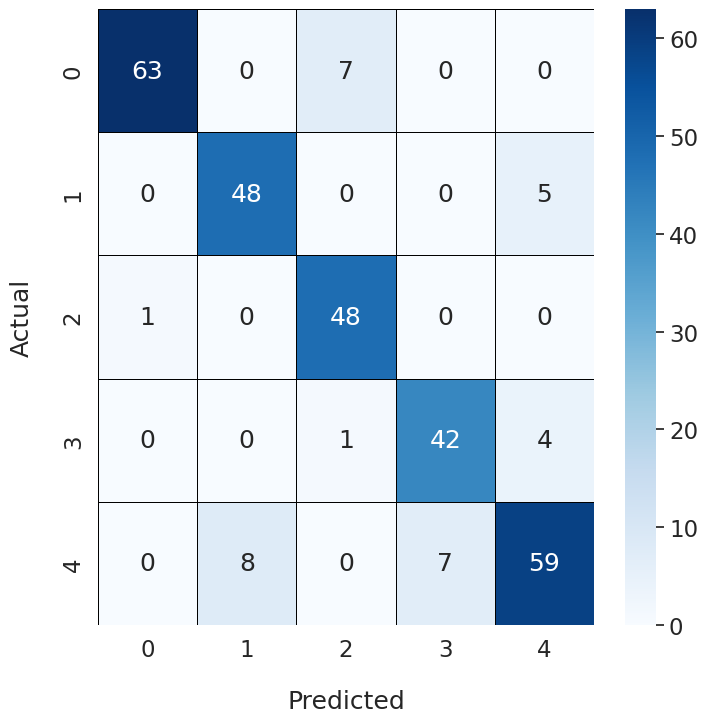

Epoch Training Time: 2215.74 seconds
Test set: Average loss: 0.5047, Accuracy: 273/323 (84.52%), F1 Score: 0.8433

Fold 8
-------
Early stopping at epoch 163 due to no improvement in validation loss.


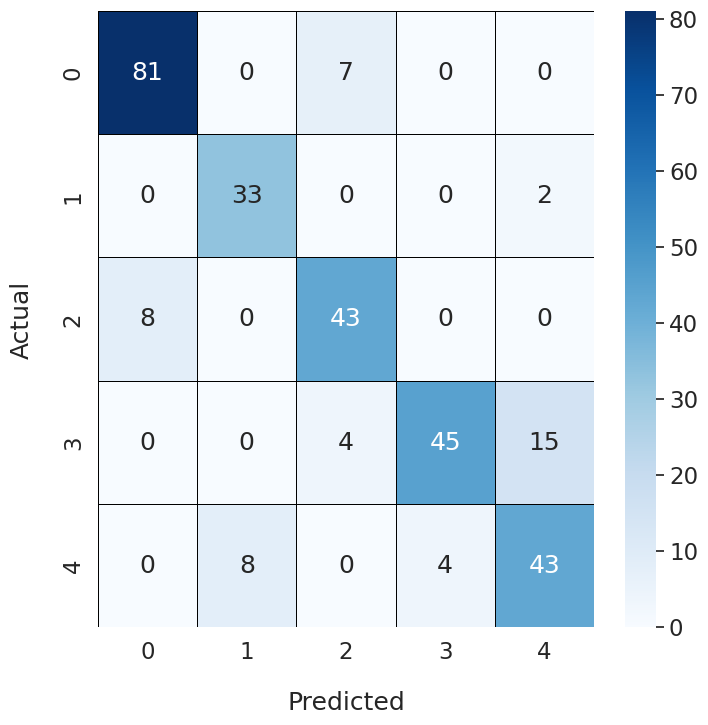

Epoch Training Time: 1730.54 seconds
Test set: Average loss: 0.4203, Accuracy: 273/323 (84.52%), F1 Score: 0.8446

Fold 9
-------
Early stopping at epoch 208 due to no improvement in validation loss.


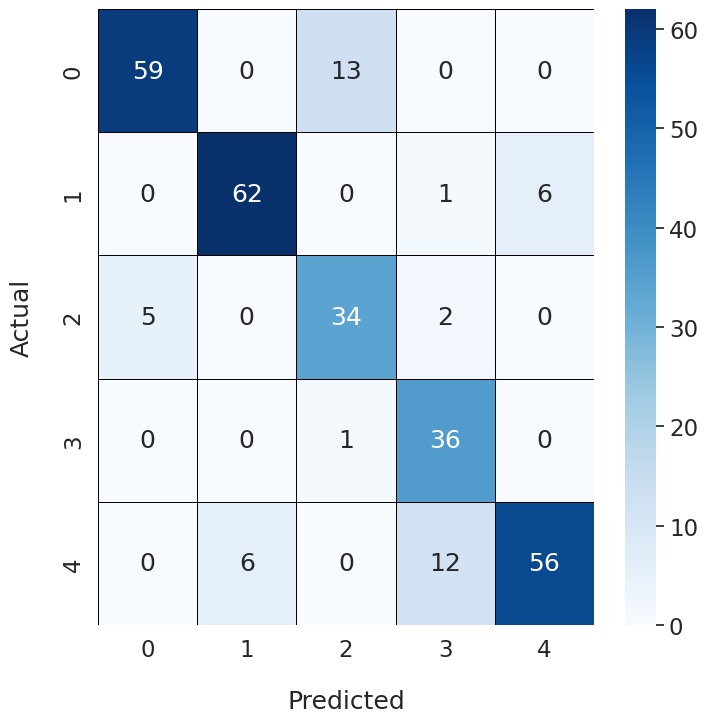

Epoch Training Time: 2204.37 seconds
Test set: Average loss: 0.4904, Accuracy: 282/323 (87.31%), F1 Score: 0.8723

Fold 10
-------
Early stopping at epoch 177 due to no improvement in validation loss.


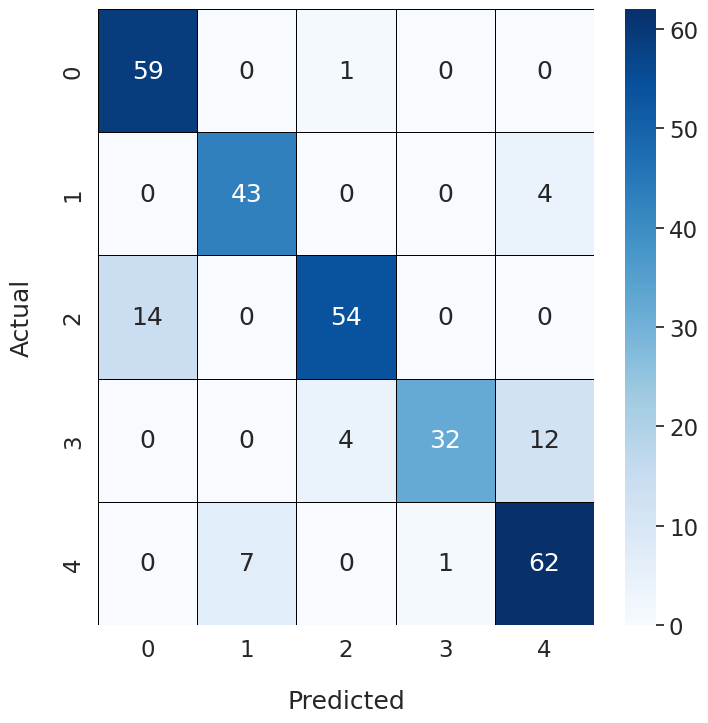

Epoch Training Time: 1878.90 seconds
Test set: Average loss: 0.4007, Accuracy: 277/323 (85.76%), F1 Score: 0.8560


Total training time for 10 folds: 19869.04 seconds


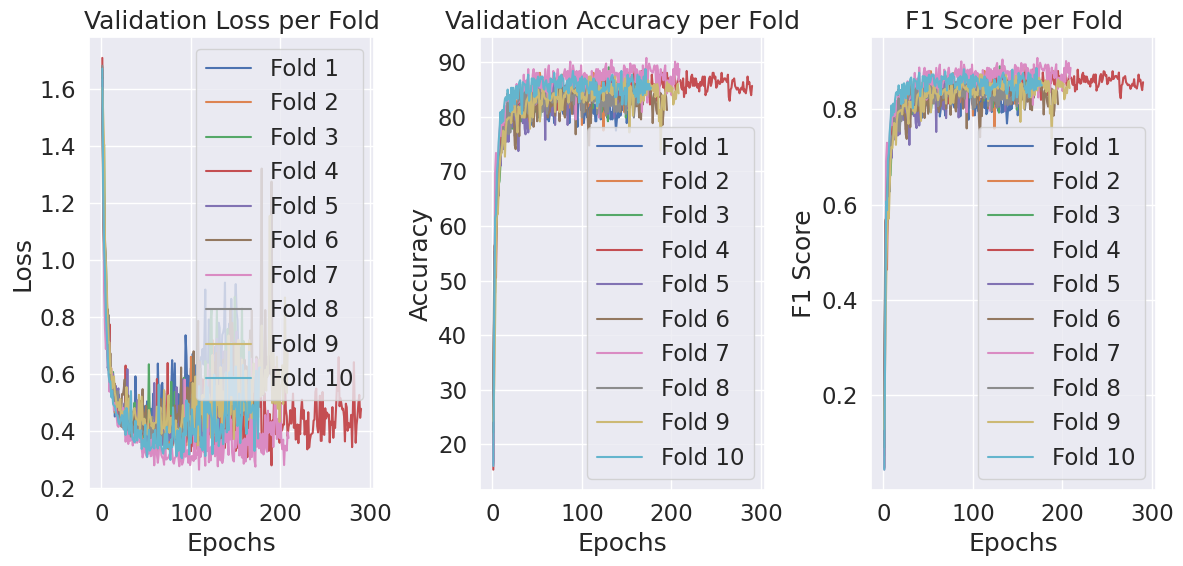

Maximum Fold Accuracy = 87.30650154798762
Maximum Fold F1 Score = 0.8722545796562171
Average Fold Accuracy = 84.89164086687306
Average Fold F1 Score = 0.8478556742968293


In [47]:
# Loop through each fold
all_fold_accuracy = []
all_fold_f1 = []
save_dir = "./result_Darknet/Fuzz_noSE"
os.makedirs(save_dir, exist_ok=True)
print_count = 0

model_save_path = "./model_Darknet/Fuzz_noSE/Fuzz_noSE.pth"
os.makedirs("./model_Darknet/Fuzz_noSE", exist_ok=True)

#log_file_path = os.path.join(save_dir, "training_log_Fuzz_noSE.txt")
#sys.stdout = open(log_file_path, 'w')

for fold, (train_idx, test_idx) in enumerate(kf.split(train_dataset)):
    print(f"Fold {fold + 1}")
    print("-------")

    best_test_loss = float('inf')
    epoch_val_loss = []
    epoch_val_acc = []
    epochs_f1_score = []

   # Define the data loaders for the current fold
    train_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(train_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    valid_loader = DataLoader(
        dataset=train_dataset,
        batch_size=batch_size,
        sampler=torch.utils.data.SubsetRandomSampler(test_idx),
        worker_init_fn=seed_worker,
        generator=g
    )
    
    
    test_loader = DataLoader(
        dataset=test_dataset,
        batch_size=batch_size,
        shuffle=True,
        worker_init_fn=seed_worker,
        generator=g
    )
    # Initialize the model and optimizer
    model = darknet53(5).to(device)
    with torch.cuda.device(0):
      macs, params = get_model_complexity_info(model, (3, 256, 256), as_strings=True,
                                             print_per_layer_stat=False, verbose=False)
      if print_count == 0:
          print(f"Model FLOPs (MACs): {macs}")
          print(f"Model Params: {params}")
          print_count += 1

    optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)

    start_time = time.time()

    # Train the model on the current fold
    for epoch in range(1, epochs+1):#----------------------------------------epochs
        train(model, device, train_loader, optimizer, epoch)
        all_targets, all_preds = evaluate(model, device, valid_loader, epoch, num_samples=len(test_idx), save_dir=save_dir, fold=fold, epoch_val_loss=epoch_val_loss, epoch_val_acc=epoch_val_acc, epochs_f1_score=epochs_f1_score, count_not_improve=epochs_no_improve, max_patience=patience)

        if epoch_val_loss[-1] < best_test_loss:  # Save model if test loss improves
            best_test_loss = epoch_val_loss[-1]
            torch.save(model.state_dict(), model_save_path)
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping at epoch {epoch} due to no improvement in validation loss.")
                conf_matrix = confusion_matrix(all_targets, all_preds)
                plt.figure(figsize=(8,8))
                sns.set(font_scale = 1.5)
                ax = sns.heatmap(
                    conf_matrix, # confusion matrix 2D array 
                    annot=True, # show numbers in the cells
                    fmt='d', # show numbers as integers
                    cbar=True, # don't show the color bar
                    cmap='Blues', # customize color map
                    linewidths=0.5,
                    linecolor='black',
                    vmax=None # to get better color contrast
                )
                ax.set_xlabel("Predicted", labelpad=20)
                ax.set_ylabel("Actual", labelpad=20)
                save_path = os.path.join(save_dir, f"training_conf_matrix_fold_{fold+1}.png")
                plt.show()
                break  # Exit the epoch loop
                
    end_time = time.time()
    epoch_training_time = end_time - start_time
    all_fold_time.append(epoch_training_time)
    print(f"Epoch Training Time: {epoch_training_time:.2f} seconds")
    
    # Save training metrics to CSV
    csv_file = os.path.join(save_dir, f"Fuzz_noSE_result_fold_{fold+1}.csv")
    with open(csv_file, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Epoch", "Validation_Loss", "Validation_Accuracy", "F1_Score"])
        for epoch in range(len(epoch_val_loss)):
            writer.writerow([epoch + 1, epoch_val_loss[epoch], epoch_val_acc[epoch], epochs_f1_score[epoch]])

    all_folds_val_loss.append(epoch_val_loss.copy())
    all_folds_val_acc.append(epoch_val_acc.copy())
    all_folds_f1.append(epochs_f1_score.copy())

    # Evaluate the model on the test set at the end of train phase--------------------------------------------------------------------------------------------
    
    best_model = darknet53(5).to(device)
    best_model.load_state_dict(torch.load(model_save_path))
    best_model.eval()
    
    test_loss = 0
    correct = 0
    all_preds = []
    all_targets = []

    criterion = nn.CrossEntropyLoss(reduction="sum")
    
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = best_model(data)
            test_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            all_preds.extend(pred.cpu().numpy().flatten())  
            all_targets.extend(target.cpu().numpy().flatten())  
            
    test_loss /= len(all_targets)
    accuracy = 100.0 * correct / len(all_targets)
    f1 = f1_score(all_targets, all_preds, average="weighted")

    all_fold_accuracy.append(accuracy)
    all_fold_f1.append(f1)
    # Print the results for the current fold
    print(f"Test set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(all_targets)} ({accuracy:.2f}%), F1 Score: {f1:.4f}\n")

#calculate total train time
total_time = sum(all_fold_time)
print(f"\nTotal training time for 10 folds: {total_time:.2f} seconds")
#for ploting----------------------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# After the training loop, plot the loss graph
plt.subplot(1, 3, 1)
for i, val_loss in enumerate(all_folds_val_loss):
    plt.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f'Fold {i+1}')
plt.title('Validation Loss per Fold')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Validation Accuracy
plt.subplot(1, 3, 2)
for i, val_acc in enumerate(all_folds_val_acc):
    plt.plot(np.arange(1, len(val_acc) + 1), val_acc, label=f'Fold {i+1}')
plt.title('Validation Accuracy per Fold')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# F1 Score
plt.subplot(1, 3, 3)
for i, f1 in enumerate(all_folds_f1):
    plt.plot(np.arange(1, len(f1) + 1), f1, label=f'Fold {i+1}')
plt.title('F1 Score per Fold')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(save_dir, "combined_metrics_all_folds.png"), dpi=300, bbox_inches='tight')
#plt.close()
    
max_fold_accuracy = np.max(all_fold_accuracy)
max_fold_f1 = np.max(all_fold_f1)
avg_fold_accuracy = np.mean(all_fold_accuracy)
avg_fold_f1 = np.mean(all_fold_f1)
print("Maximum Fold Accuracy =", max_fold_accuracy)
print("Maximum Fold F1 Score =", max_fold_f1)
print("Average Fold Accuracy =", avg_fold_accuracy)
print("Average Fold F1 Score =", avg_fold_f1)
#sys.stdout.close()
#sys.stdout = sys.__stdout__

In [48]:
clear_all_memory()

Memory cleared and environment reset!
